# **ML_2. Supervised Learning**

### **1. Ответь на вопросы**

***i. Выведите аналитическое решение задачи регрессии. Используйте векторную форму уравнения.***  
*Derive an analytical solution to the regression problem. Use a vector form of the equation.*  

$$
\boxed{\hat{\boldsymbol{\beta}} = (X^TX)^{-1}X^T\mathbf{y}}
$$

---

***ii. Какие изменения произойдут в решении при добавлении L1- и L2-регуляризации к функции потерь?***  
*What changes in the solution when L1 and L2 regularizations are added to the loss function.*  

Регуляризация используется для борьбы с переобучением и уменьшения сложности модели.
Идея состоит в том, чтобы при обучении минимизировать не только ошибку предсказаний, но и дополнительный штраф за слишком большие значения весов.


**Bias (свободный член)** обычно не регуляризуется, поэтому в реализации штраф применяется только к весам признаков.

К исходной функции потерь добавляется регуляризационный штраф $R(\boldsymbol{\beta})$, а итоговая задача оптимизации принимает вид:  

$$
\min_{\boldsymbol{\beta}} L_{\text{reg}}(\boldsymbol{\beta}) = \min_{\boldsymbol{\beta}} \Big( L(\boldsymbol{\beta}) + \lambda R(\boldsymbol{\beta}) \Big)
$$

*L* - исходная функция потерь (ошибка модели на обучающих данных);  
$R(\boldsymbol{\beta})$ - регуляризационный штраф, зависящий от вектора весов $\boldsymbol{\beta}$;  
$\lambda$ - коэффициент (сила) регуляризации. Чем больше $\lambda$, тем сильнее модель штрафуется за величину весов (в sklearn обозначается как $\alpha$).  

В случае *L2*-регуляризации (Ridge)** штраф равен сумме квадратов коэффициентов (квадрат $L_2$-нормы вектора весов):  

$$
L_{L2}(\boldsymbol{\beta}) = \|\mathbf{y} - X\boldsymbol{\beta}\|_2^2 + \lambda \|\boldsymbol{\beta}\|_2^2 = \|\mathbf{y} - X\boldsymbol{\beta}\|^2 + \lambda \sum_{j=1}^{p} \beta_j^2
$$

* **Изменение в самом решении:** для линейной регрессии задача имеет строго аналитическое решение в замкнутом виде. Главное изменение — к матрице $X^TX$ добавляется сдвиг $\lambda I$, что делает её гарантированно обратимой и решает проблему мультиколлинеарности:  

$$
\hat{\boldsymbol{\beta}}_{L2} = (X^TX + \lambda I)^{-1}X^T\mathbf{y}
$$

В случае **L1-регуляризации (Lasso)** штраф равен сумме модулей коэффициентов ($L_1$ норма вектора весов):  

$$
L_{L1}(\boldsymbol{\beta}) = \|\mathbf{y} - X\boldsymbol{\beta}\|_2^2 + \lambda \|\boldsymbol{\beta}\|_1 = \|\mathbf{y} - X\boldsymbol{\beta}\|^2 + \lambda \sum_{j=1}^{p} |\beta_j|
$$


* **Изменение в самом решении:** из-за наличия модулей функция потерь становится недифференцируемой в нуле, поэтому аналитического решения в замкнутом виде не существует. Задача решается численными методами оптимизации (например, координатным спуском), а получаемое векторное решение становится разреженным , то есть содержит много весов, строго равных нулю.


---

***iii. Объясните, почему L1-регуляризация часто используется для отбора признаков. Почему после обучения модели остается много весов, равных 0?***   
*Explain why L1 regularization is often used to select features. Why are there many weights equal to 0 after the model is fit?* 

* **Причина зануления весов:** геометрически штраф L1 имеет форму излома (острые вершины в точке $\beta_j = 0$). При минимизации функции потерь линии уровня ошибки чаще всего пересекают ограничения именно на осях координат, где один или несколько коэффициентов **точно равны нулю**.
* **Практический смысл:** веса при слабых, зашумленных или избыточных признаках обнуляются ($\beta_j = 0$), что приводит к автоматическому **отбору признаков** и исключению их из модели. В отличие от L1, регуляризация L2 лишь уменьшает веса, но не делает их строго нулевыми.


---
***iV. Объясните, как можно использовать те же модели (линейная регрессия, гребневая регрессия и т. д.), но при этом обеспечить возможность учета нелинейных зависимостей***  
*Explain how you can use the same models (Linear regression, Ridge, etc.) but make it possible to fit nonlinear dependencies.*

Линейная регрессия линейна **только по параметрам $\boldsymbol{\beta}$**, но не по исходным признакам. Для учета нелинейности применяется **генерация признаков (feature engineering)**:

1. Исходные признаки трансформируются с помощью нелинейных базисных функций $\phi(x)$. 
2. На вход стандартной линейной модели (или Ridge/Lasso) подается новая матрица признаков $\Phi$:
   * **Полиномы:** $x \to (x, x^2, x^3)$
   * **Нелинейные преобразования:** $x \to (\log x, \exp(x), \sin x)$
   * **Взаимодействия:** $(x_1, x_2) \to (x_1, x_2, x_1 x_2)$

Модель находит веса $\boldsymbol{\beta}$ с помощью того же аналитического решения $\hat{\boldsymbol{\beta}} = (\Phi^T\Phi)^{-1}\Phi^T\mathbf{y}$, сохраняя вычислительную простоту, но описывая сложные нелинейные границы.

*What changes in the solution when L1 and L2 regularizations are added to the loss function.*  





[Подробные ответы](ML_2_2_Linear_Regression.%20Задание.md)

### **2. Введение**.  
*Выполните всю предварительную обработку данных из предыдущего урока.*

#### ***i. Импорт библиотек***

In [1]:
# автоматическая перезагрузка внешних скриптов
%load_ext autoreload
%autoreload 2

# Стандартные библиотеки
import numpy as np
import pandas as pd
import ipywidgets as widgets

import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import ElasticNet, Lasso, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import warnings
from sklearn.exceptions import ConvergenceWarning
from IPython.display import Markdown, display, HTML, Math

# кастомные утилиты
from ml_utils import (
    universal_styler,
    highlight_results,
    save_metrics_checkpoint,
    load_metrics_checkpoint,
)

#### ***ii. Загрузка train и test датасетов. (read train and test parts)***

In [2]:
data_train = pd.read_json("../datasets/train.json")
print(f"""Количество строк: {data_train.shape[0]}
Количество столбцов: {data_train.shape[1]}""")

Количество строк: 49352
Количество столбцов: 15


In [3]:
data_test = pd.read_json("../datasets/test.json")
print(f"""Количество строк: {data_test.shape[0]}
Количество столбцов: {data_test.shape[1]}""")

Количество строк: 74659
Количество столбцов: 14


In [4]:
percentile_1 = data_train["price"].quantile(0.01)
percentile_99 = data_train["price"].quantile(0.99)

data_train = data_train[
    (data_train["price"] > percentile_1) & (data_train["price"] < percentile_99)
].copy()

price_lowest, price_highest = data_train["price"].min(), data_train["price"].max()


data_train["interest_level"] = data_train["interest_level"].map(
    {"low": 0, "medium": 1, "high": 2}
)
data_train.shape

(48343, 15)

In [5]:
data_train_backup = data_train.copy()

In [6]:
data_test = data_test[
    (data_test["price"] >= price_lowest) & (data_test["price"] <= price_highest)
].copy()

bath_max = data_train["bathrooms"].max()
bed_max = data_train["bedrooms"].max()
data_test = data_test[
    (data_test["bathrooms"] <= bath_max) & (data_test["bedrooms"] <= bed_max)
].copy()

data_test.shape

(73175, 14)

### **3. Введение в анализ данных, часть 2**.  

#### ***i. Давайте создадим дополнительные характеристики для повышения качества модели. Рассмотрим столбец под названием «Features». Он содержит список основных особенностей текущей квартиры.***

In [7]:
cols = ["bathrooms", "bedrooms", "features"]
data_train[cols].head(10)

,bathrooms,bedrooms,features
4,1.0,1,"[Dining Room, Pre-War, Laundry in Building, Di..."
6,1.0,2,"[Doorman, Elevator, Laundry in Building, Dishw..."
9,1.0,2,"[Doorman, Elevator, Laundry in Building, Laund..."
10,1.5,3,[]
15,1.0,0,"[Doorman, Elevator, Fitness Center, Laundry in..."
16,1.0,3,"[Doorman, Elevator, Loft, Dishwasher, Hardwood..."
18,2.0,3,"[Fireplace, Laundry in Unit, Dishwasher, Hardw..."
19,1.0,0,"[Elevator, Laundry in Building, Dishwasher, Ha..."
23,0.0,1,[Hardwood Floors]
32,3.0,3,"[Cats Allowed, Dogs Allowed]"


#### ***ii. Удалите из столбца неиспользуемые символы ([,], ', ", и пробел).***

*после pd.read_json столбец features это не строка, а список Python. Поэтому для применения строковых методов нужно привести к строке.*

In [8]:
print(type(data_train["features"].iloc[0]))

<class 'list'>


In [9]:
data_train["features"].head(3)

4    [Dining Room, Pre-War, Laundry in Building, Di...
6    [Doorman, Elevator, Laundry in Building, Dishw...
9    [Doorman, Elevator, Laundry in Building, Laund...
Name: features, dtype: object

In [10]:
data_train["features"] = data_train["features"].astype(str)
data_train["features"].iloc[0]

"['Dining Room', 'Pre-War', 'Laundry in Building', 'Dishwasher', 'Hardwood Floors', 'Dogs Allowed', 'Cats Allowed']"

In [11]:
print(type(data_train["features"].iloc[0]))

<class 'str'>


In [12]:
for ch in ["[", "]", "'", '"', " "]:
    data_train["features"] = data_train["features"].str.replace(ch, "", regex=False)

data_train["features"].head(3)

4    DiningRoom,Pre-War,LaundryinBuilding,Dishwashe...
6    Doorman,Elevator,LaundryinBuilding,Dishwasher,...
9    Doorman,Elevator,LaundryinBuilding,LaundryinUn...
Name: features, dtype: str

In [13]:
print(
    "Всего пустых строк  в data_train датасете:", (data_train["features"] == "").sum()
)

Всего пустых строк  в data_train датасете: 3106


#### ***iii. Получите все значения в каждом списке и соберите результат в один большой список для всего набора данных. Для этого можно использовать DataFrame.iterrows().***

In [14]:
feature_list = []
for _, row in data_train.iterrows():
    if row["features"] != "":
        feature_list.extend(row["features"].split(","))

In [15]:
print("Длина списка:", len(feature_list))

Длина списка: 262377


In [16]:
feature_list[:5]

['DiningRoom', 'Pre-War', 'LaundryinBuilding', 'Dishwasher', 'HardwoodFloors']

#### ***iv. Сколько уникальных значений содержит список результатов?***

In [17]:
len(set(feature_list))

1529

#### ***v. Давайте познакомимся с новой библиотекой — Collections. С помощью этого пакета вы сможете эффективно получать количественную статистику по вашим данным.***

#### ***vi. Составьте список самых популярных функций из нашего обширного перечня и выберите 20 лучших на данный момент.***

In [18]:
from collections import Counter

In [19]:
feature_counts = Counter(feature_list)

In [20]:
top_20_pairs = feature_counts.most_common(20)
top_20_pairs

[('Elevator', 25375),
 ('HardwoodFloors', 23146),
 ('CatsAllowed', 23135),
 ('DogsAllowed', 21652),
 ('Doorman', 20479),
 ('Dishwasher', 20081),
 ('NoFee', 17793),
 ('LaundryinBuilding', 16082),
 ('FitnessCenter', 12989),
 ('Pre-War', 8971),
 ('LaundryinUnit', 8437),
 ('RoofDeck', 6417),
 ('OutdoorSpace', 5132),
 ('DiningRoom', 4890),
 ('HighSpeedInternet', 4223),
 ('Balcony', 2898),
 ('SwimmingPool', 2643),
 ('LaundryInBuilding', 2564),
 ('NewConstruction', 2504),
 ('Terrace', 2177)]

> **Заметка по оптимизации:**
> В рамках данного задания согласно ТЗ был выполнен пайплайн "Список -> Строка -> Очистка -> Разделение через iterrows()".
> Однако на реальных больших датасетах использование `iterrows()` является антипаттерном из-за низкой скорости работы циклов Python. В реальной практике этот же результат эффективнее и быстрее получить в две строки кода с помощью векторного метода `data_train["features"].explode()` и встроенного в Pandas метода `.str.join()`, что позволило бы избежать посимвольной очистки текста и сэкономило бы память.

ну и решается в пару строк как бонус все :)

In [21]:
# explode превращает DataFrame со списками в плоский ряд всех элементов
feature_list_2 = data_train_backup["features"].explode()

feature_counts_2 = Counter(feature_list_2)
top_20_pairs_2 = feature_counts_2.most_common(
    21
)  # т.к здесь не режу пустые строки, они в подсчете  и их  (nan, 3106)
top_20_pairs_2

[('Elevator', 25375),
 ('Hardwood Floors', 23146),
 ('Cats Allowed', 23135),
 ('Dogs Allowed', 21652),
 ('Doorman', 20479),
 ('Dishwasher', 20081),
 ('No Fee', 17793),
 ('Laundry in Building', 16082),
 ('Fitness Center', 12989),
 ('Pre-War', 8971),
 ('Laundry in Unit', 8437),
 ('Roof Deck', 6417),
 ('Outdoor Space', 5132),
 ('Dining Room', 4890),
 ('High Speed Internet', 4223),
 (nan, 3106),
 ('Balcony', 2898),
 ('Swimming Pool', 2643),
 ('Laundry In Building', 2564),
 ('New Construction', 2504),
 ('Terrace', 2177)]

***Ранее на каггле был другой датасет. Сейчас обновленный. Больше, чем был до этого.***

*пустые строки не учитываю на моменте сбора feature_list

#### ***vii. Если все правильно, вы должны получить следующие значения: 'Elevator', 'CatsAllowed', 'HardwoodFloors', 'DogsAllowed', 'Doorman', 'Dishwasher', 'NoFee', 'LaundryinBuilding', 'FitnessCenter', 'Pre-War', 'LaundryinUnit', 'RoofDeck', 'OutdoorSpace', 'DiningRoom', 'HighSpeedInternet', 'Balcony', 'SwimmingPool', 'LaundryInBuilding', 'NewConstruction', 'Terrace'.***

данные наименования фич совпадают с полученными (см.выше).

#### ***vi. Теперь создайте 20 новых признаков на основе 20 наиболее часто встречающихся значений: 1, если значение находится в столбце "Feature", в противном случае 0.***
*Now create 20 new features based on the top 20 values: 1 if the value is in the "Feature" column, otherwise 0.*

In [22]:
top_20 = [name for name, _ in top_20_pairs]
top_20[:3]

['Elevator', 'HardwoodFloors', 'CatsAllowed']

In [23]:
splits = data_train["features"].str.split(",")
type(splits)

pandas.Series

In [24]:
for feature in top_20:
    data_train[feature] = splits.apply(lambda lst: int(feature in lst))

In [25]:
data_train[top_20].head(3)

,Elevator,HardwoodFloors,CatsAllowed,DogsAllowed,Doorman,Dishwasher,NoFee,LaundryinBuilding,FitnessCenter,Pre-War,LaundryinUnit,RoofDeck,OutdoorSpace,DiningRoom,HighSpeedInternet,Balcony,SwimmingPool,LaundryInBuilding,NewConstruction,Terrace
4,0,1,1,1,0,1,0,1,0,1,0,0,0,1,0,0,0,0,0,0
6,1,1,0,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0
9,1,1,0,0,1,1,0,1,0,0,1,0,0,0,0,0,0,0,0,0


#### ***ix. Расширьте наш набор признаков, добавив «ванные комнаты», «спальни», и создайте специальную переменную feature_list со всеми названиями признаков. Теперь у нас есть 22 значения. Все модели должны быть обучены на этих 22 признаках.***
Extend our feature set with 'bathrooms', 'bedrooms' and create a special variable feature_list with all feature names. Now we have 22 values. All models should be trained on these 22 features.

In [26]:
feature_list = top_20 + ["bathrooms", "bedrooms"]
print("Всего признаков:", len(feature_list))

Всего признаков: 22


In [27]:
X_train = data_train[feature_list]
y_train = data_train["price"]

In [28]:
data_test[cols].head(5)

,bathrooms,bedrooms,features
0,1.0,1,"[Elevator, Laundry in Building, Laundry in Uni..."
1,1.0,2,"[Pre-War, Dogs Allowed, Cats Allowed]"
2,1.0,0,"[Pre-War, Dogs Allowed, Cats Allowed]"
3,1.0,2,"[Hardwood Floors, Dogs Allowed, Cats Allowed]"
5,1.0,1,"[Roof Deck, Doorman, Elevator, Fitness Center,..."


In [29]:
for feature in top_20:
    data_test[feature] = data_test["features"].apply(
        lambda lst: int(feature in [x.replace(" ", "") for x in lst])
    )

In [30]:
data_test[top_20].sum().head(3)

Elevator          38227
HardwoodFloors    34994
CatsAllowed       35052
dtype: int64

In [31]:
# feature_list = top_20 + ["bathrooms", "bedrooms"]
data_test[feature_list].head(3)

,Elevator,HardwoodFloors,CatsAllowed,DogsAllowed,Doorman,Dishwasher,NoFee,LaundryinBuilding,FitnessCenter,Pre-War,...,OutdoorSpace,DiningRoom,HighSpeedInternet,Balcony,SwimmingPool,LaundryInBuilding,NewConstruction,Terrace,bathrooms,bedrooms
0,1,1,0,0,0,1,0,1,0,0,...,1,0,0,0,0,0,0,0,1.0,1
1,0,0,1,1,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,1.0,2
2,0,0,1,1,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,1.0,0


In [32]:
y_test = data_test["price"]
X_test = data_test[feature_list]

### **4. Реализация моделей — Линейная регрессия**.  


#### ***i. Реализуйте класс Python для алгоритма линейной регрессии с двумя основными методами — fit и predict. Используйте стохастический градиентный спуск (SGD) для поиска оптимальных весов модели. Для лучшего понимания рекомендуем реализовать отдельные версии алгоритма с аналитическим решением и нестохастическим градиентным спуском.***
implement a Python class for a linear regression algorithm with two basic methods — fit and predict. Use stochastic gradient descent (SGD) to find optimal model weights. For better understanding, we recommend implementing separate versions of the algorithm with the analytical solution and non-stochastic gradient descent under the hood.

#### ***1) Алгоритм с аналитическим решением.***

Аналитическое решение задачи регрессии.  

$$
\boxed{
\hat{\boldsymbol{\beta}}
=
(X^TX)^{-1}X^T\mathbf y
}
$$

#### ***Как решается обратная матрица на практике или почему обычно применяют метод pinv (а не inv) или lstsq, и почему det не диагностика в float64***

В этом проекте X = 22 признака + столбец единиц = 23×23,
матрица полноранговая → XᵀX обратима, np.linalg.inv работает; np.linalg.pinv
здесь страховка (на полноранговой матрице она совпадает с inv). Незаменимой
pinv становится при вырожденной или плохо обусловленной матрице: в ML_1
полином 10 степени от двух базовых признаков (квадратные признаки там остались
только проверкой гипотезы, в модель не пошли) дал 66 столбцов ранга 44 < 66 →
XᵀX сингулярна, np.linalg.inv бросила бы LinAlgError: Singular matrix.

**Почему det не диагностика в float64** (математически det = 0 ⇔ вырожденность):
* масштаб: det(cA) = cⁿ·det(A), при n = 66 отличная матрица даёт det ~1e-46
  или 1e+46 просто из-за масштаба;
* overflow/underflow: det легко уходит в нуль или бесконечность;
* det не показывает степень обусловленности: у катастрофически плохой матрицы
  |det| = 1 (напр., diag(1e10, 1e-10)).

Корректная диагностика — cond = σ_max/σ_min: теряется ~log10(cond) знаков
точности, у float64 запас ~16 знаков, значит cond ~1e16 даёт чистый шум при
det = 1; cond(XᵀX) = cond(X)², поэтому на XᵀX смотрят особенно строго.

**Почему pinv.** Псевдообратная (Мура–Пенроуза) считается через SVD: нулевые
и близкие к нулю сингулярные значения отбрасываются → работает на вырожденных
и плохо обусловленных матрицах, возвращая псевдорешение (least squares)
минимальной нормы. sklearn.LinearRegression решает через SVD
(scipy.linalg.lstsq), поэтому обучилась бы даже на ранге 44.

**Практическое правило:** проверять cond, а не det; решать через pinv/lstsq,
а не через inv.

In [33]:
# ones — столбец (вектор) из единиц длиной len(data_train):
# по одной единице на каждый объект, чтобы свободный коэффициент (bias)
# стал обычным весом при столбце-единице
# ones = np.ones((len(data_train), 1))
# ones = np.ones((len(data_train), 1))
# ones

In [34]:
# np.hstack([data_train, ones])#

In [35]:
class LinearRegressionAnalytic:
    """Линейная регрессия через аналитическое решение."""

    COND_THRESHOLD = 1e12

    def _prepare(self, X):
        """Приводит X к float и добавляет столбец единиц для bias."""
        X = np.asarray(X, dtype=float)
        return np.hstack([X, np.ones((len(X), 1))])

    def fit(self, X, y):
        """Обучает и сохраняет веса."""
        X_b = self._prepare(X)
        y = np.asarray(y, dtype=float)

        XtX = X_b.T @ X_b

        self.cond_ = np.linalg.cond(XtX)
        self.rank_ = np.linalg.matrix_rank(XtX)

        if self.cond_ > self.COND_THRESHOLD:
            warnings.warn(
                f"X^T X плохо обусловлена: cond={self.cond_:.3e}, "
                f"rank={self.rank_} из {XtX.shape[0]}. "
                "Коэффициенты могут быть неустойчивыми.",
                UserWarning,
            )

        self.w_ = np.linalg.pinv(XtX) @ X_b.T @ y

        return self

    def predict(self, X):
        if not hasattr(self, "w_"):
            raise ValueError("Эта модель еще не обучена. Сначала вызовите метод .fit()")

        return self._prepare(X) @ self.w_

In [36]:
lr_analytic = LinearRegressionAnalytic().fit(X_train, y_train)
y_pred_tr_analytic = lr_analytic.predict(X_train)
y_pred_te_analytic = lr_analytic.predict(X_test)

mae_tr_analytic = mean_absolute_error(y_train, y_pred_tr_analytic)
rmse_tr_analytic = mean_squared_error(y_train, y_pred_tr_analytic) ** 0.5

mae_te_analytic = mean_absolute_error(y_test, y_pred_te_analytic)
rmse_te_analytic = mean_squared_error(y_test, y_pred_te_analytic) ** 0.5

In [37]:
print("вектор весов:", lr_analytic.w_.shape)
display(Markdown(f"обусловленность матрицы $X^T X = {lr_analytic.cond_:.3f}$"))

вектор весов: (23,)


обусловленность матрицы $X^T X = 483.436$

In [38]:
print("Метрики качества кастомной аналитической модели линейной регрессии")
print("-" * 70)
print(f"train: mae = {mae_tr_analytic:<10.3f} rmse = {rmse_tr_analytic:<10.3f}")
print(f"test:  mae = {mae_te_analytic:<10.3f} rmse = {rmse_te_analytic:<10.3f}")

Метрики качества кастомной аналитической модели линейной регрессии
----------------------------------------------------------------------
train: mae = 708.737    rmse = 1027.263  
test:  mae = 709.901    rmse = 1021.206  


* **rank = 23** равен числу столбцов, то есть $X^T X$ полноранговая и обратимая:
  строгой мультиколлинеарности и вырожденности нет. Все столбцы линейно независимы, аналитическое решение существует и единственно.

* ***$cond(X^T X) ≈ 483.44$*** — матрица хорошо обусловлена: cond(X) = sqrt(483.44) ≈ 22,
  потеря точности при решении системы порядка $lg483 ≈ 2.7$  десятичных знака
  из ~16 доступных у float64. Это ничтожно мало, порог предупреждения ($1e^{12}$)
  не превышен, поэтому решение численно устойчиво и ему можно доверять.

#### ***2) Алгоритм с нестохастическим градиентным спуском***

#### Математика нестохастического (полного) градиентного спуска

Главное отличие от аналитической версии: там веса получались за одну операцию
обращения матрицы, здесь это итеративный процесс.

**Задача.** Минимизируем функцию потерь по всей обучающей выборке:

$$ L(w) = \frac{1}{2n} \|Xw - y\|^2 = \frac{1}{2} \cdot \underbrace{\frac{1}{n}\|Xw - y\|^2}_{MSE} $$

Коэффициент $\frac{1}{2n}$ состоит из двух частей с разными ролями:
* $\frac{1}{n}$ — нормировка: сумма квадратов ошибок становится средней,
  поэтому потеря и градиент не зависят от размера выборки, градиент равен
  среднему градиентов по объектам, и lr переносим между датасетами;
* $\frac{1}{2}$ — удобство дифференцирования: производная квадрата дает
  множитель 2, который сокращается с этой половинкой.

Минимизация $L$ равносильна минимизации MSE: константный множитель не меняет
положение минимума. В аналитическом решении коэффициент вообще не требовался
(уравнение $\nabla L = 0$ не меняется от умножения на константу), в спуске он
масштабирует шаг, и этот масштаб поглощается lr.

**Градиент.** В аналитическом решении потеря уже была раскрыта и
продифференцирована по вектору весов (там он обозначен $\boldsymbol{\beta}$,
здесь $w$; это один и тот же вектор):

$$ \frac{\partial L}{\partial \boldsymbol{\beta}} = -2 X^T \mathbf{y} + 2 X^T X \boldsymbol{\beta}
\quad \text{для } L = \|\mathbf{y} - X\boldsymbol{\beta}\|^2 \text{ без нормирующего множителя} $$

Там производную приравняли к нулю и решили $X^T X \boldsymbol{\beta} = X^T \mathbf{y}$
относительно весов, так получилось точное решение за один шаг. Здесь производную
к нулю не приравниваем, а используем как направление шага. С множителем
$\frac{1}{2n}$ это та же производная, умноженная на константу:

$$ \nabla_w L(w) = \frac{1}{2n}\left(2 X^T X w - 2 X^T \mathbf{y}\right) = \frac{1}{n} X^T (X w - \mathbf{y}) $$

Градиент указывает направление наибыстрейшего роста функции потерь, поэтому
шаг делаем в противоположную сторону. Именно этот градиент считает код класса:
grad = X_b.T @ residual / n.

**Обновление весов.** На каждой итерации:

$$ w \leftarrow w - lr \cdot \nabla_w L(w) = w - \frac{lr}{n} X^T (X w - \mathbf{y}) $$

Метод называется нестохастическим (full-batch), потому что градиент вычисляется
точно по всем n объектам выборки на каждом шаге, а не по одному случайному
объекту (SGD) и не по случайному подмножеству (mini-batch).

**Критерии остановки.** 

В классе используются два условия: $|\nabla L(w)|_2 < tol$
Если градиент стал достаточно мал, дальнейшие изменения весов будут небольшими, поэтому обучение можно завершить.

Второе условие - max_iter. Это максимальное число итераций и одновременно защита от слишком долгого обучения, если выбранный lr не позволяет быстро достичь заданного tol.

**Скорость сходимости.** На квадратичной функции спуск сходится линейно,
и число итераций зависит от числа обусловленности $cond(X^T X)$: чем оно больше,
тем медленнее спуск и тем сильнее «зигзаги» в узком овраге. Для обеспечения
стабильной сходимости градиентного спуска нужно предварительно масштабировать входные данные (что сделано по тз в п.7).

In [39]:
class LinearRegressionGD:
    """Линейная регрессия через полный градиентный спуск.
    На каждой итерации градиент считается по всей обучающей выборке:
        L(w) = 1/(2n) * ||Xw - y||**2
        grad = X^T(Xw - y) / n
        w -= lr * grad
    """

    def __init__(self, lr=0.1, tol=1e-8, max_iter=10000):
        self.lr = lr
        self.tol = tol
        self.max_iter = max_iter

    def _prepare(self, X):
        """добавляет столбец единиц для bias."""
        X = np.asarray(X, dtype=float)
        return np.hstack([X, np.ones((len(X), 1))])

    def fit(self, X, y):
        y = np.asarray(y, dtype=float)

        X_b = self._prepare(X)
        n = len(y)

        self.w_ = np.zeros(X_b.shape[1])

        iteration = 0

        for iteration in range(self.max_iter):
            residual = X_b @ self.w_ - y
            grad = X_b.T @ residual / n

            self.w_ -= self.lr * grad
            # ранний выход по норме градиента
            if np.linalg.norm(grad) < self.tol:
                break
        self.n_iter_ = iteration + 1

        return self

    def predict(self, X):
        if not hasattr(self, "w_"):
            raise ValueError(
                "Эта модель еще не обучена. Сначала вызовите метод .fit(X, y)"
            )
        return self._prepare(X) @ self.w_

-------------------------

Условие np.linalg.norm(grad) < self.tol отвечает за ранний останов алгоритма, если он уже достиг плато.

* На текущей итерации grad - это вектор градиента функции потерь.
* Его Евклидова норма **norm(grad)** показывает общую величину (длину) вектора градиента.
* Если норма градиента становится меньше заданного порога **tol**, это означает, что функция потерь вышла на плато (находимся в минимуме). Следующий шаг изменения весов будет ничтожно малым, продолжать вычисления нет смысла  - выходим через break.
*  Если алгоритм не успевает достичь сходимости, обучение  остановится по достижении **max_iter**.

-----------------------

In [40]:
gd = LinearRegressionGD(
    lr=0.1,
    tol=1e-8,
    max_iter=20000,
).fit(X_train, y_train)

y_pred_tr_gd = gd.predict(X_train)
y_pred_te_gd = gd.predict(X_test)

print("итераций:", gd.n_iter_)

mae_tr_gd = mean_absolute_error(y_train, y_pred_tr_gd)
rmse_tr_gd = mean_squared_error(y_train, y_pred_tr_gd) ** 0.5

mae_te_gd = mean_absolute_error(y_test, y_pred_te_gd)
rmse_te_gd = mean_squared_error(y_test, y_pred_te_gd) ** 0.5

итераций: 12508


In [41]:
print("Метрики качества кастомной модели градиентного спуска для линейной регрессии")
print("-" * 80)
print(f"train: mae = {mae_tr_gd:<10.3f} rmse = {rmse_tr_gd:<10.3f}")
print(f"test:  mae = {mae_te_gd:<10.3f} rmse = {rmse_te_gd:<10.3f}")

Метрики качества кастомной модели градиентного спуска для линейной регрессии
--------------------------------------------------------------------------------
train: mae = 708.737    rmse = 1027.263  
test:  mae = 709.901    rmse = 1021.206  


*в файле ml copy.ipynb в этом классе была добавлена нормализация  и там алгоритм отработал за 2024 итерации с теми же результатами.*

#### ***3) Стохастический градиентный спуск (SGD)***

#### Математика стохастического градиентного спуска (SGD). лекция Балакирева. Добрый, добрый ИИ. (см.обсидиан)

В полном градиентном спуске градиент считается по всей выборке. В SGD на каждом
шаге используется только один случайно выбранный объект.

**Потеря на одном объекте:** $L_i(w)=\frac{1}{2}(x_i\cdot w-y_i)^2.$

Обозначим остаток: $r_i=x_i\cdot w-y_i.$

Тогда градиент потери одного объекта: $\nabla_w L_i(w)=r_i x_i.$

Поэтому один шаг SGD имеет вид: $w_{new}= w_{old}-lr_t\,r_i x_i.$

Каждый следующий шаг использует веса, полученные на предыдущем шаге.


**Почему используется один объект.** При случайном равновероятном выборе объекта градиент отдельного объекта является
оценкой полного градиента:

$$
\mathbb E_i[\nabla L_i(w)]
=
\frac1n\sum_{i=1}^{n}\nabla L_i(w)
=
\nabla L(w).
$$

Поэтому отдельные шаги SGD шумные, но в среднем направлены в сторону полного
градиента.

Один проход по всей выборке в случайном порядке называется **эпохой**.

Перемешивание объектов перед каждой эпохой позволяет не проходить выборку
каждый раз в одном и том же порядке.

**Расписание шага.** При постоянном lr шум отдельных градиентов сохраняется. Поэтому в SGD часто используют уменьшающийся шаг.

В классе реализованы четыре варианта:

1) $\text{const:}\qquad lr_t=lr_0,$
2) $\text{linear:}\qquad
lr_t=lr_0\max\left(0,1-\frac{t}{T}\right),$
3) $\text{exp:}\qquad
lr_t=lr_0e^{-t/T},$
4) $\text{harmonic:}\qquad
lr_t=\frac{lr_0}{1+t/T}.$

Здесь t — номер глобального обновления, а T — горизонт расписания, равный
$T=max\_epochs\cdot n.$

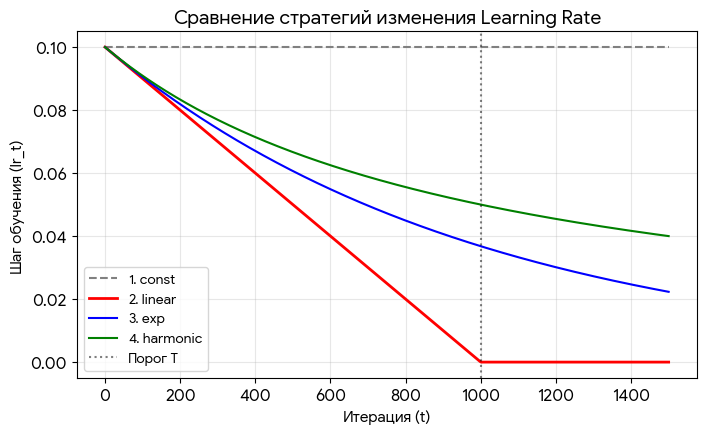

**Останов обучения.** останавливаем по бюджету эпох (max_epochs). 
В отличие от полного GD, последовательность потерь отдельных объектов в SGD
шумная, поэтому критерий вида $L_t < tol$ не является хорошим универсальным критерием остановки. Кроме того, абсолютный уровень потерь зависит от данных. Поэтому сначала мы изучаем сам алгоритм SGD и простой критерий по числу эпох, а мониторинг сходимости рассматриваем отдельно.

**Мониторинг SGD.** Во время SGD точный функционал по всей выборке пересчитывать на каждом шаге
дорого: это требует прохода по всем объектам. Поэтому для мониторинга можно использовать экспоненциальное скользящее среднее (EMA) потерь отдельных объектов:

$Q_t=\lambda L_t+(1-\lambda)Q_{t-1}.$
где
$L_t = \frac{1}{2} (x_t \cdot w - y_t)^2$ - потеря на текущем объекте, 

а $\lambda = \frac{2}{N+1}$ задаёт условное окно памяти N

EMA не участвует в обновлении весов. Это только инструмент мониторинга. Оно сглаживает шумную последовательность потерь и позволяет наблюдать за процессом обучения. (это из лекции Балакирева - применять не стала)

---

**Таким образом разница трех подходов:**  

Analytic - получает веса сразу  
GD - повторяет полный градиент  
SGD - повторяет градиент одного объекта  

---

In [42]:
# недетерминированная версия алгоритма
class SimpleLinearRegressionSGD:
    """Линейная регрессия через через стохастический градиентный спуск SGD.
    Перед каждой эпохой объекты случайно перемешиваются.
    На каждом шаге:
        residual = x_i · w - y_i
        w -= lr * residual * x_i
    """

    def __init__(
        self,
        lr=0.01,
        max_epochs=50,
    ):
        self.lr = lr
        self.max_epochs = max_epochs

    def _prepare(self, X):
        X = np.asarray(X, dtype=float)
        return np.hstack([X, np.ones((len(X), 1))])

    def fit(self, X, y):
        y = np.asarray(y, dtype=float)
        X_b = self._prepare(X)
        self.w_ = np.zeros(X_b.shape[1])

        for _ in range(self.max_epochs):
            # создаём индексы и случайно перемешиваем их
            indexes = np.arange(len(y))
            np.random.shuffle(indexes)

            # один проход по всей выборке
            for i in indexes:
                x_i = X_b[i]
                residual = x_i @ self.w_ - y[i]
                self.w_ -= self.lr * residual * x_i
        return self

    def predict(self, X):
        if not hasattr(self, "w_"):
            raise ValueError("Эта модель еще не обучена. Сначала вызовите метод .fit()")
        return self._prepare(X) @ self.w_

#### ***ii. Что такое детерминированная модель? Сделайте SGD детерминированным.***
What is determenistic model? Make SGD determenistic.

*Детерминированная модель при одинаковых входных данных и настройках всегда выдаёт одинаковый результат. В предыдущей реализации SimpleLinearRegressionSGD порядок объектов перемешивается без фиксированного seed, поэтому результаты обучения могут отличаться (пример ниже). Чтобы сделать SGD детерминированным, необходимо зафиксировать seed генератора случайных чисел.*

In [43]:
sgd_simple_model1 = SimpleLinearRegressionSGD()
sgd_simple_model2 = SimpleLinearRegressionSGD()

sgd_simple_model1.fit(X_train, y_train)
sgd_simple_model2.fit(X_train, y_train)

are_close = np.allclose(sgd_simple_model1.w_, sgd_simple_model2.w_)

print(f"Одинаковые веса: {'да' if are_close else 'нет'}")
print(
    "Максимальное различие:",
    np.max(np.abs(sgd_simple_model1.w_ - sgd_simple_model2.w_)),
)

Одинаковые веса: нет
Максимальное различие: 220.34956024826505


***случайный порядок перемешивания объектов  в SGD** приводит к хаотичным скачкам весов. В результате две одинаковые модели сходятся в совершенно разные точки пространства  с высоким максимальным расхождением весов, представляющим собой трехзначное число (кстати в файле ml copy в этом классе было добавлено маштабирование данных и там различие всего **0.164**)*

In [44]:
weights_df = pd.DataFrame(
    {
        "Weights Model 1": sgd_simple_model1.w_,
        "Weights Model 2": sgd_simple_model2.w_,
        "Absolute Diff": np.abs(sgd_simple_model1.w_ - sgd_simple_model2.w_),
    }
)
print("Различие весов при двух запусках недетерминированного алгоритма SGD")
display(weights_df.head(5))

Различие весов при двух запусках недетерминированного алгоритма SGD


,Weights Model 1,Weights Model 2,Absolute Diff
0,216.576929,264.927439,48.350510
1,-71.809425,-132.227143,60.417718
2,-109.129285,111.220275,220.349560
3,95.579915,152.815067,57.235152
4,601.037755,658.664029,57.626274


***Для того чтобы результаты обучения модели были воспроизводимыми от запуска к запуску:***

1. Введен параметр random_state (по умолчанию = 21) в конструктор класса.
2. Создается объект-генератор случайных чисел rng = np.random.default_rng(self.random_state) в методе fit перед циклами прохождения эпох.
3. Генератор используется на каждой эпохе для перемешивания индексов данных перед проходом по датасету с помощью rng.permutation(n).

***Также добавлена опция изменения скорости обучения*** через параметр schedule (по дефолту schedule="harmonic") заставляет шаг lr_t постепенно уменьшаться от обновления к обновлению. Это позволяет модели делать большие шаги в начале обучения для быстрого поиска минимума, постепенно уменьшаясь при подходе к точке минимума (что снизит хаотичные скачки весов как в модели simpleLinearRegressionSGD).

In [45]:
# детерминированнй алгоритм стохастического градиентного спуска
class LinearRegressionSGD:
    """Линейная регрессия через стохастический градиентный спуск.
    На каждом шаге используется один случайный объект:
        residual = x_i · w - y_i
        w -= lr_t * residual * x_i
    Один проход по всей выборке в случайном порядке называется эпохой.
    """

    def __init__(
        self,
        lr=0.1,
        schedule="harmonic",
        max_epochs=50,
        random_state=21,
    ):
        self.lr = lr
        self.schedule = schedule
        self.max_epochs = max_epochs
        self.random_state = random_state

    def _prepare(self, X):
        X = np.asarray(X, dtype=float)
        return np.hstack([X, np.ones((len(X), 1))])

    def _learning_rate(self, t, T):
        """Возвращает шаг lr_t для текущего обновления."""
        if self.schedule == "const":
            return self.lr
        if self.schedule == "linear":
            return self.lr * max(0.0, 1 - t / T)
        if self.schedule == "exp":
            return self.lr * np.exp(-t / T)
        if self.schedule == "harmonic":
            return self.lr / (1 + t / T)
        raise ValueError(
            "schedule должен быть одним из: 'const', 'linear', 'exp', 'harmonic'"
        )

    def fit(self, X, y):
        y = np.asarray(y, dtype=float)
        X_b = self._prepare(X)
        n = len(y)
        T = self.max_epochs * n
        # функция создания генератора вместо старого np.random.seed()
        rng = np.random.default_rng(self.random_state)
        self.w_ = np.zeros(X_b.shape[1])

        t = 0

        for _ in range(self.max_epochs):
            for i in rng.permutation(n):
                lr_t = self._learning_rate(t, T)

                x_i = X_b[i]
                residual = x_i @ self.w_ - y[i]
                self.w_ -= lr_t * residual * x_i
                t += 1
        self.n_updates_ = t

        return self

    def predict(self, X):
        if not hasattr(self, "w_"):
            raise ValueError("Эта модель еще не обучена. Сначала вызовите метод .fit()")
        return self._prepare(X) @ self.w_

---
#### Доказательство детерминированности класса LinearRegressionSGD

In [46]:
sgd1 = LinearRegressionSGD(
    lr=0.01,
    schedule="harmonic",
    max_epochs=50,
    random_state=21,
)

sgd2 = LinearRegressionSGD(
    lr=0.01,
    schedule="harmonic",
    max_epochs=50,
    random_state=21,
)

sgd1.fit(X_train, y_train)
sgd2.fit(X_train, y_train);

In [47]:
print("Одинаковые веса:", np.allclose(sgd1.w_, sgd2.w_))
print("Максимальное различие:", np.max(np.abs(sgd1.w_ - sgd2.w_)))

Одинаковые веса: True
Максимальное различие: 0.0


---

In [48]:
sgd = LinearRegressionSGD(
    lr=0.01,
    schedule="harmonic",
    max_epochs=50,
    random_state=21,
).fit(X_train, y_train)

y_pred_tr_sgd = sgd.predict(X_train)
y_pred_te_sgd = sgd.predict(X_test)

mae_tr_sgd = mean_absolute_error(y_train, y_pred_tr_sgd)
rmse_tr_sgd = mean_squared_error(y_train, y_pred_tr_sgd) ** 0.5

mae_te_sgd = mean_absolute_error(y_test, y_pred_te_sgd)
rmse_te_sgd = mean_squared_error(y_test, y_pred_te_sgd) ** 0.5

In [49]:
print(
    "Метрики качества кастомной модели стохастического градиентного спуска для линейной регрессии"
)
print("-" * 80)
print(f"train: mae = {mae_tr_sgd:<10.3f} rmse = {rmse_tr_sgd:<10.3f}")
print(f"test:  mae = {mae_te_sgd:<10.3f} rmse = {rmse_te_sgd:<10.3f}")

Метрики качества кастомной модели стохастического градиентного спуска для линейной регрессии
--------------------------------------------------------------------------------
train: mae = 714.719    rmse = 1073.254  
test:  mae = 715.991    rmse = 1065.702  


In [50]:
data = {
    "Method": ["Analytic", "Gradient Descent", "Stochastic GD"],
    "MAE train": [mae_tr_analytic, mae_tr_gd, mae_tr_sgd],
    "MAE test": [mae_te_analytic, mae_te_gd, mae_te_sgd],
    "RMSE train": [rmse_tr_analytic, rmse_tr_gd, rmse_tr_sgd],
    "RMSE test": [rmse_te_analytic, rmse_te_gd, rmse_te_sgd],
}

summary_df = pd.DataFrame(data).set_index("Method")
summary_df.style.format("{:.3f}")

,MAE train,MAE test,RMSE train,RMSE test
Method,,,,
Analytic,708.737,709.901,1027.263,1021.206
Gradient Descent,708.737,709.901,1027.263,1021.206
Stochastic GD,714.719,715.991,1073.254,1065.702


#### ***iii. Определите коэффициент R² и реализуйте функцию для его вычисления.***
Define the R squared (R2) coefficient and implement a function to calculate it.

**Коэффициент детерминации** - это статистическая метрика, оценивающая долю дисперсии зависимой переменной, которая объясняется предсказаниями модели или насколько качественнее наша модель находит закономерности в данных по сравнению с наивным предсказанием в виде среднего арифметического ($\bar{y}$).

#### Математическая формула:

$$R^2 = 1 - \frac{SS_{res}}{SS_{tot}} = 1 - \frac{\sum_{i=1}^{n} (y_i - \hat{y}_i)^2}{\sum_{i=1}^{n} (y_i - \bar{y})^2}$$

Где:
* $y_i$ — истинные значения целевого признака.
* $\hat{y}_i$ — предсказанные значения модели.
* $\bar{y}$ — среднее арифметическое истинных значений целевого признака ($\bar{y} = \frac{1}{n}\sum_{i=1}^{n}y_i$).
* $SS_{res}$ (*Residual Sum of Squares*) — сумма квадратов остатков (ошибок) модели.
* $SS_{tot}$ (*Total Sum of Squares*) — общая сумма квадратов отклонений от среднего значения (дисперсия целевой переменной).

#### Интерпретация значений:
* **$R^2 = 1.0$** — идеальная модель, предсказания полностью совпадают с реальными ответами.
* **$0 < R^2 < 1.0$** — модель работает лучше, чем предсказание среднего значения. Чем ближе к 1, тем выше качество.
* **$R^2 = 0.0$** — модель предсказывает на уровне среднего арифметического (не находит никакой структуры в данных).
* **$R^2 < 0.0$** — модель работает хуже, чем обычное среднее значение. В случае SGD это обычно сигнализирует о расхождении градиента (слишком большой шаг `lr`).


In [51]:
def r2_score(y_true, y_pred):
    """Вычисляет коэффициент детерминации R^2."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)

    if ss_tot == 0:  # если y_true состоит из одинаковых констант
        return 0.0
    return 1.0 - (ss_res / ss_tot)

#### ***iv. С помощью вашего алгоритма сделайте прогнозы и оцените модель, используя метрики MAE, RMSE и R2.***
Make predictions with your algorithm and estimate the model with MAE, RMSE and R2 metrics.

In [52]:
def calculate_print_and_save_metrics(
    model_name, y_true_tr, y_pred_tr, y_true_te, y_pred_te, results_dict=None
):
    mae_tr = mean_absolute_error(y_true_tr, y_pred_tr)
    mae_te = mean_absolute_error(y_true_te, y_pred_te)
    rmse_tr = mean_squared_error(y_true_tr, y_pred_tr) ** 0.5
    rmse_te = mean_squared_error(y_true_te, y_pred_te) ** 0.5
    r2_tr = float(r2_score(y_true_tr, y_pred_tr))
    r2_te = float(r2_score(y_true_te, y_pred_te))

    metrics_list = [mae_tr, mae_te, rmse_tr, rmse_te, r2_tr, r2_te]

    print(f"Эксперимент: {model_name}")
    print("-" * 60)
    print(f"train: mae = {mae_tr:<10.3f} rmse = {rmse_tr:<10.3f} r2 = {r2_tr:<10.3f}")
    print(f"test:  mae = {mae_te:<10.3f} rmse = {rmse_te:<10.3f} r2 = {r2_te:<10.3f}")
    print("-" * 60 + "\n")

    if results_dict is not None:
        results_dict[model_name] = metrics_list
    else:
        return metrics_list

In [53]:
# два отдельных словаря для своих моделей и библиотечных
#  в первой версии ноутбука было все вместе с тегами _mySGD и _sklearn
my_models = {}
sk_models = {}

In [54]:
calculate_print_and_save_metrics(
    "linear_regression_mySGD", y_train, y_pred_tr_sgd, y_test, y_pred_te_sgd, my_models
)

Эксперимент: linear_regression_mySGD
------------------------------------------------------------
train: mae = 714.719    rmse = 1073.254   r2 = 0.542     
test:  mae = 715.991    rmse = 1065.702   r2 = 0.541     
------------------------------------------------------------



#### ***v. Инициализируйте функцию LinearRegression() из sklearn.linear_model, обучите модель и выполните прогнозирование для обучающей и тестовой частей, как в предыдущем уроке.***
Initialize LinearRegression() from sklearn.linear_model, fit the model, and predict the training and test parts as in the previous lesson.

In [55]:
lr = LinearRegression()
lr.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](22,)","[ 228.1 ,-170.24, -77.02,..., 174.48,1559.2 , 464.18]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](22,)","['Elevator','HardwoodFloors','CatsAllowed',...,'Terrace','bathrooms', 'bedrooms']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,611.3
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,22
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(22)


In [56]:
y_pred_lr_train = lr.predict(X_train)
y_pred_lr_test = lr.predict(X_test)

In [57]:
calculate_print_and_save_metrics(
    "linear_regression", y_train, y_pred_lr_train, y_test, y_pred_lr_test, sk_models
)

Эксперимент: linear_regression
------------------------------------------------------------
train: mae = 708.737    rmse = 1027.263   r2 = 0.580     
test:  mae = 709.901    rmse = 1021.206   r2 = 0.579     
------------------------------------------------------------



In [58]:
sk_models

{'linear_regression': [708.7371183299155,
  709.900590038001,
  1027.2628793038969,
  1021.2055608633134,
  0.5802691109575654,
  0.5788386726413894]}

#### ***vi. Сравните показатели качества и убедитесь, что разница невелика (между вашей реализацией и sklearn).***
Compare the quality metrics and make sure the difference is small (between your implementations and sklearn).

In [59]:
def diff(m1, m2):
    diff = abs(m1 - m2)
    pct = (diff / max(m1, m2) * 100) if max(m1, m2) != 0 else 0
    return pct

In [60]:
diffs = []

for i in range(len(sk_models["linear_regression"])):
    for j in range(len(my_models["linear_regression_mySGD"])):
        if i == j:
            diffs.append(
                diff(
                    sk_models["linear_regression"][i],
                    my_models["linear_regression_mySGD"][j],
                )
            )

In [61]:
row_names = ["MAE Train", "MAE Test", "RMSE Train", "RMSE Test", "R2 Train", "R2 Test"]

display(
    pd.DataFrame(
        data={
            "Sklearn": sk_models["linear_regression"],
            "mySGD": my_models["linear_regression_mySGD"],
            "разница в %": diffs,
        },
        index=row_names,
    )
    # словарь с индивидуальным форматом для каждого столбца
    .style.format({"Sklearn": "{:.3f}", "mySGD": "{:.3f}", "разница в %": "{:.1f}%"})
)


,Sklearn,mySGD,разница в %
MAE Train,708.737,714.719,0.8%
MAE Test,709.901,715.991,0.9%
RMSE Train,1027.263,1073.254,4.3%
RMSE Test,1021.206,1065.702,4.2%
R2 Train,0.580,0.542,6.6%
R2 Test,0.579,0.541,6.5%


#### ***vii. Сохраните метрики, как и в предыдущем уроке, в таблице со столбцами model, train, test для таблицы MAE, таблицы RMSE и коэффициента R2.***
Store the metrics as in the previous lesson in a table with columns model, train, test for MAE table, RMSE table, and R2 coefficient.

In [187]:
result_MAE = pd.DataFrame(columns=["model", "train", "test"])
result_RMSE = pd.DataFrame(columns=["model", "train", "test"])
result_R2 = pd.DataFrame(columns=["model", "train", "test"])

In [ ]:
result_MAE_myModels = pd.DataFrame(columns=["model", "train", "test"])
result_RMSE_myModels = pd.DataFrame(columns=["model", "train", "test"])
result_R2_myModels = pd.DataFrame(columns=["model", "train", "test"])

In [189]:
def append_results_toDFs(
    model_name,
    mae_tr,
    mae_te,
    rmse_tr,
    rmse_te,
    r2_tr,
    r2_te,
    target_mae=None,
    target_rmse=None,
    target_r2=None,
):
    """апдейт датафреймов с защитой от дубликатов и динамическим выбором таблиц.
    По умолчанию запись в глобальные result_MAE, result_RMSE, result_R2.
    """
    dest_mae = result_MAE if target_mae is None else target_mae
    dest_rmse = result_RMSE if target_rmse is None else target_rmse
    dest_r2 = result_R2 if target_r2 is None else target_r2

    def update_df(df, values):
        """функция для обновления строки по индексу или добавления новой."""

        mask = df["model"] == model_name
        if mask.any():
            # если модель с таким именем уже есть — перезаписываем её строго по маске
            df.loc[mask] = [values]
        else:
            df.loc[len(df)] = values

    update_df(dest_mae, [model_name, mae_tr, mae_te])
    update_df(dest_rmse, [model_name, rmse_tr, rmse_te])
    update_df(dest_r2, [model_name, r2_tr, r2_te])

In [190]:
append_results_toDFs("linear_regression", *sk_models["linear_regression"])

append_results_toDFs(
    "linear_regression_mySGD",
    *my_models["linear_regression_mySGD"],
    target_mae=result_MAE_myModels,
    target_rmse=result_RMSE_myModels,
    target_r2=result_R2_myModels,
)

In [191]:
print("Итоговая таблица result_MAE")
display(result_MAE.style.format("{:.3f}", subset=["train", "test"]).hide(axis="index"))


print("\nИтоговая таблица result_RMSE")
display(result_RMSE.style.format("{:.3f}", subset=["train", "test"]).hide(axis="index"))

print("\nИтоговая таблица result_R2")
display(result_R2.style.format("{:.3f}", subset=["train", "test"]).hide(axis="index"))

Итоговая таблица result_MAE


model,train,test
linear_regression,708.737,709.901



Итоговая таблица result_RMSE


model,train,test
linear_regression,1027.263,1021.206



Итоговая таблица result_R2


model,train,test
linear_regression,0.580,0.579


### **5. Реализация моделей с регуляризацией —  Ridge, Lasso, ElasticNet** 
Regularized models implementation - Ridge, Lasso, ElasticNet.  

#### ***i. Реализуйте алгоритмы Ridge, Lasso и ElasticNet: расширьте функцию потерь с помощью L2, L1 и обеих регуляризаций соответственно.***
Implement Ridge, Lasso, ElasticNet algorithms: extend the loss function with L2, L1 and both regularizations accordingly.

### Математическая справка перед реализацией моделей (SGD)

В стохастическом градиентном спуске (SGD) минимизация функции потерь и обновление весов происходят итерационно на основе **одного случайного объекта** $i$ на каждом шаге $t$:

$$
w^{(t+1)} = w^{(t)} - \eta_t \, \nabla L_{\text{reg}}(w)
$$

Для одного объекта базовая ошибка МНК и её градиент равны:

$$
L(w) = \frac{1}{2}(x_i \cdot w - y_i)^2 \quad \Longrightarrow \quad \nabla L(w) = (x_i \cdot w - y_i)\, x_i
$$

Полный градиент на каждом шаге объединяет ошибку на текущем объекте и градиент регуляризации $\nabla L_{\text{reg}}(w) = \nabla L(w) + \alpha \nabla R(w)$ (свободный член $w_b$ в конце вектора весов не регуляризуется).

---

***Ridge (L2) Функция потерь (для объекта i):***

$$
L_{\text{Ridge}}(w) = \frac{1}{2}(x_i \cdot w - y_i)^2 + \frac{\alpha}{2}\|w\|_2^2
$$

- **Градиент регуляризации:** $\nabla R(w) = w$
- **Полный градиент шага:** $\nabla L_{\text{Ridge}}(w) = (x_i \cdot w - y_i)\, x_i + \alpha\, w$
- **Обновление весов:** $w^{(t+1)} = w^{(t)} - \eta_t \left[ (x_i \cdot w - y_i)\, x_i + \alpha\, w \right]$

---

***Lasso (L1) Функция потерь (для объекта i):***

$$
L_{\text{Lasso}}(w) = \frac{1}{2}(x_i \cdot w - y_i)^2 + \alpha\|w\|_1
$$

- **Градиент регуляризации:** $\nabla R(w) = \operatorname{sign}(w)$
- **Полный градиент шага:** $\nabla L_{\text{Lasso}}(w) = (x_i \cdot w - y_i)\, x_i + \alpha\, \operatorname{sign}(w)$
- **Обновление весов:** $w^{(t+1)} = w^{(t)} - \eta_t \left[ (x_i \cdot w - y_i)\, x_i + \alpha\, \operatorname{sign}(w) \right]$

---

***ElasticNet (L1 + L2) Функция потерь (для объекта i):***

$$
L_{\text{EN}}(w) = \frac{1}{2}(x_i \cdot w - y_i)^2 + \alpha \left( \rho \|w\|_1 + \frac{1-\rho}{2} \|w\|_2^2 \right)
$$

- **Градиент регуляризации:** $\nabla R(w) = \rho\, \operatorname{sign}(w) + (1-\rho)\, w$
- **Полный градиент шага:** $\nabla L_{\text{EN}}(w) = (x_i \cdot w - y_i)\, x_i + \alpha \left( \rho\, \operatorname{sign}(w) + (1-\rho)\, w \right)$
- **Обновление весов:** $w^{(t+1)} = w^{(t)} - \eta_t \left[ (x_i \cdot w - y_i)\, x_i + \alpha \left( \rho\, \operatorname{sign}(w) + (1-\rho)\, w \right) \right]$

*Здесь $\rho$ (l1_ratio) — доля L1-регуляризации, $0 \le \rho \le 1$.*

---

*в класс буду передавать через параметры ridge, lasso, elasticnet (градиент = alpha * (l1_ratio * np.sign(w) + (1 - l1_ratio) * w))*

In [193]:
class RegularizedLinearRegressionSGD:
    """Линейная регрессия через стохастический градиентный спуск с регуляризацией."""

    def __init__(
        self,
        alpha=1.0,  # коэффициент регуляризации (вместо лямбда)
        penalty="ridge",  # 'ridge', 'lasso', 'elasticnet' или None
        l1_ratio=0.5,  # параметр ро для elasticNet
        lr=0.1,
        schedule="harmonic",
        max_epochs=50,
        random_state=21,
    ):
        self.alpha = alpha
        self.penalty = penalty
        self.l1_ratio = l1_ratio
        self.lr = lr
        self.schedule = schedule
        self.max_epochs = max_epochs
        self.random_state = random_state

    def _prepare(self, X):
        X = np.asarray(X, dtype=float)

        return np.hstack([X, np.ones((len(X), 1))])

    def _learning_rate(self, t, T):
        """Возвращает шаг lr_t для текущего обновления."""
        if self.schedule == "const":
            return self.lr
        if self.schedule == "linear":
            return self.lr * max(0.0, 1 - t / T)
        if self.schedule == "exp":
            return self.lr * np.exp(-t / T)
        if self.schedule == "harmonic":
            return self.lr / (1 + t / T)

        raise ValueError(
            "schedule должен быть одним из: 'const', 'linear', 'exp', 'harmonic'"
        )

    def fit(self, X, y):
        """Обучает модель стохастическим градиентным спуском с регуляризацией."""
        y = np.asarray(y, dtype=float)
        X_b = self._prepare(X)
        n = len(y)
        T = self.max_epochs * n
        rng = np.random.default_rng(self.random_state)
        self.w_ = np.zeros(X_b.shape[1])
        t = 0

        for _ in range(self.max_epochs):
            for i in rng.permutation(n):
                lr_t = self._learning_rate(t, T)
                x_i = X_b[i]
                residual = x_i @ self.w_ - y[i]

                # градиент функции потерь для текущего объекта
                dW_loss = residual * x_i

                # градиент регуляризации с занулением bias (последний элемент весов)
                w_reg = self.w_.copy()
                w_reg[-1] = 0.0

                if self.penalty == "ridge":
                    dW_reg = self.alpha * w_reg
                elif self.penalty == "lasso":
                    dW_reg = self.alpha * np.sign(w_reg)
                elif self.penalty == "elasticnet":
                    dW_reg = self.alpha * (
                        self.l1_ratio * np.sign(w_reg) + (1 - self.l1_ratio) * w_reg
                    )
                else:
                    dW_reg = np.zeros_like(w_reg)

                dW_full = dW_loss + dW_reg
                self.w_ -= lr_t * dW_full

                t += 1

        self.n_updates_ = t

        return self

    def predict(self, X):
        if not hasattr(self, "w_"):
            raise ValueError(
                "Эта модель еще не обучена. Сначала вызовите метод .fit(X, y)"
            )
        return self._prepare(X) @ self.w_

#### ***ii. С помощью вашего алгоритма сделайте прогнозы и оцените модель, используя метрики MAE, RMSE и R2.***
Make predictions with your algorithm and estimate the model with MAE, RMSE and R2 metrics.

---
***для L2-регуляризации:***

In [194]:
rsgd_ridge = RegularizedLinearRegressionSGD(
    max_epochs=200, schedule="exp", lr=0.05
).fit(X_train, y_train)

y_pred_rsgd_ridge_train = rsgd_ridge.predict(X_train)
y_pred_rsgd_ridge_test = rsgd_ridge.predict(X_test)

In [195]:
calculate_print_and_save_metrics(
    "ridge_mySGD",
    y_train,
    y_pred_rsgd_ridge_train,
    y_test,
    y_pred_rsgd_ridge_test,
    results_dict=my_models,
)

Эксперимент: ridge_mySGD
------------------------------------------------------------
train: mae = 891.591    rmse = 1261.695   r2 = 0.367     
test:  mae = 890.988    rmse = 1254.614   r2 = 0.364     
------------------------------------------------------------



---

***для L1-регуляризации:***

In [196]:
rsgd_lasso = RegularizedLinearRegressionSGD(
    penalty="lasso", max_epochs=200, schedule="exp", lr=0.01, alpha=0.1
).fit(X_train, y_train)
y_pred_rsgd_lasso_train = rsgd_lasso.predict(X_train)
y_pred_rsgd_lasso_test = rsgd_lasso.predict(X_test)

In [197]:
calculate_print_and_save_metrics(
    "lasso_mySGD",
    y_train,
    y_pred_rsgd_lasso_train,
    y_test,
    y_pred_rsgd_lasso_test,
    results_dict=my_models,
)

Эксперимент: lasso_mySGD
------------------------------------------------------------
train: mae = 705.288    rmse = 1029.602   r2 = 0.578     
test:  mae = 705.973    rmse = 1022.901   r2 = 0.577     
------------------------------------------------------------



---

***для elasticNet-регуляризации:***

In [198]:
rsgd_elastic = RegularizedLinearRegressionSGD(
    penalty="elasticnet", alpha=0.1, max_epochs=200, schedule="exp", lr=0.01
).fit(X_train, y_train)
y_pred_rsgd_elastic_train = rsgd_elastic.predict(X_train)
y_pred_rsgd_elastic_test = rsgd_elastic.predict(X_test)

In [199]:
calculate_print_and_save_metrics(
    "elasticnet_mySGD",
    y_train,
    y_pred_rsgd_elastic_train,
    y_test,
    y_pred_rsgd_elastic_test,
    results_dict=my_models,
)

Эксперимент: elasticnet_mySGD
------------------------------------------------------------
train: mae = 706.129    rmse = 1049.990   r2 = 0.561     
test:  mae = 706.622    rmse = 1043.382   r2 = 0.560     
------------------------------------------------------------



#### ***iii. Инициализируйте функции Ridge(), Lasso() и ElasticNet() из sklearn.linear_model, обучите модель и сделайте прогнозы для обучающей и тестовой выборок, как в предыдущем уроке.***
Initialize Ridge(), Lasso(), and ElasticNet() from sklearn.linear_model, fit the model, and make predictions for the training and test samples as in the previous lesson.

---
***для L2-регуляризации:***

In [200]:
ridge_sklearn = Ridge().fit(X_train, y_train)
y_pred_ridge_sk_train = ridge_sklearn.predict(X_train)
y_pred_ridge_sk_test = ridge_sklearn.predict(X_test)

In [201]:
calculate_print_and_save_metrics(
    "ridge",
    y_train,
    y_pred_ridge_sk_train,
    y_test,
    y_pred_ridge_sk_test,
    results_dict=sk_models,
)

Эксперимент: ridge
------------------------------------------------------------
train: mae = 708.734    rmse = 1027.263   r2 = 0.580     
test:  mae = 709.897    rmse = 1021.206   r2 = 0.579     
------------------------------------------------------------



---
***для L1-регуляризации:***

In [202]:
lasso_sklearn = Lasso().fit(X_train, y_train)
y_pred_lasso_sk_train = lasso_sklearn.predict(X_train)
y_pred_lasso_sk_test = lasso_sklearn.predict(X_test)

In [203]:
calculate_print_and_save_metrics(
    "lasso",
    y_train,
    y_pred_lasso_sk_train,
    y_test,
    y_pred_lasso_sk_test,
    results_dict=sk_models,
)

Эксперимент: lasso
------------------------------------------------------------
train: mae = 708.383    rmse = 1027.455   r2 = 0.580     
test:  mae = 709.531    rmse = 1021.259   r2 = 0.579     
------------------------------------------------------------



---
***для ElasticNet-регуляризации:***

In [204]:
elastic_sklearn = ElasticNet().fit(X_train, y_train)
y_pred_elastic_sk_train = elastic_sklearn.predict(X_train)
y_pred_elastic_sk_test = elastic_sklearn.predict(X_test)

In [205]:
calculate_print_and_save_metrics(
    "elasticnet",
    y_train,
    y_pred_elastic_sk_train,
    y_test,
    y_pred_elastic_sk_test,
    results_dict=sk_models,
)

Эксперимент: elasticnet
------------------------------------------------------------
train: mae = 804.298    rmse = 1180.302   r2 = 0.446     
test:  mae = 804.966    rmse = 1174.030   r2 = 0.443     
------------------------------------------------------------



#### ***iv. Сравните показатели качества и убедитесь, что разница невелика (между вашими реализациями и sklearn).***
Compare quality metrics and make sure the difference is small (between your implementations and sklearn).

In [206]:
display(
    pd.DataFrame(
        data={
            "Sklearn_ridge": sk_models["ridge"],
            "mySGD_ridge": my_models["ridge_mySGD"],
            "Sklearn_lasso": sk_models["lasso"],
            "mySGD_lasso": my_models["lasso_mySGD"],
            "Sklearn_elasticnet": sk_models["elasticnet"],
            "mySGD_elasticnet": my_models["elasticnet_mySGD"],
        },
        index=row_names,
    ).style.format(lambda x: f"{x:.3f}" if isinstance(x, (int, float)) else x)
)

,Sklearn_ridge,mySGD_ridge,Sklearn_lasso,mySGD_lasso,Sklearn_elasticnet,mySGD_elasticnet
MAE Train,708.734,891.591,708.383,705.288,804.298,706.129
MAE Test,709.897,890.988,709.531,705.973,804.966,706.622
RMSE Train,1027.263,1261.695,1027.455,1029.602,1180.302,1049.990
RMSE Test,1021.206,1254.614,1021.259,1022.901,1174.030,1043.382
R2 Train,0.580,0.367,0.580,0.578,0.446,0.561
R2 Test,0.579,0.364,0.579,0.577,0.443,0.560


**Вывод по Ridge:** Кастомная модель сходится без признаков переобучения - метрики на обучении и тесте практически совпадают   (показатели MAE и RMSE). При базовых параметрах кастомный стохастический градиентный спуск выдавал коэффициент **R2=0.253**, однако ручной подбор гиперпараметров: **200** эпох, стартовый шаг **0.05** и **экспоненциальное затухание**, позволил заметно улучшить качество, подняв показатель до **0.364**. Разница с аналитическим решением sclearn обьясняется тем, что пообъектный случайный перебор в градиентном спуске требует очень долгой и тонкой настройки, чтобы догнать точную матричную формулу, по которой стандартная библиотека произодит свои вычисения.

**Вывод по Lasso:** Кастомная модель показывает отличную сходимость и стабильность - метрики MAE и RMSE практически идентичны на обучении и тесте, подтверждая отсутствие переобучения. Первоначальный штраф альфа=1.0 слишком сильно подавлял веса признаков, ухужшая качество. Однако ручной подбор гиперпараметров (ослабление силы штрафа до **0.1**, стартовый шаг **0.01** на **200** эпохах с **экспоненциальным затуханием**) позволил полностью раскрыть потенциал алгоритма: коэффициент R2 вырос до **0.577**, а абсолютные ошибки MAE и RMSE значительно снизились, вплотную приблизившись к результатам аналитического решения sclearn.

**Вывод по ElasticNet:** Модель продемонстрировала высокую стабильность - метрики на обучении и тесте практически совпадают. Благодаря сбалансированному сочетанию L1 и L2 штрафов (при l1_ratio=0.5), ослаблению силы регуляризации до **0.1**, стартовому шагу **0.01** и **200** эпохам с **экспоненциальным затуханием**, удалось достичь коэффициента R2 = **0.560**.  Модель показала хороший результат, незначительно уступив чистому Lasso (L1).

#### ***v. Сохраните метрики, как и в предыдущем уроке, в таблице со столбцами model, train, test для таблицы MAE, таблицы RMSE и коэффициента R2.***
Store the metrics as in the previous lesson in a table with columns model, train, test for MAE table, RMSE table, and R2 coefficient.

In [207]:
for model_name, metrics in sk_models.items():
    append_results_toDFs(model_name, *metrics)

In [208]:
for model_name, metrics in my_models.items():
    append_results_toDFs(
        model_name,
        *metrics,
        target_mae=result_MAE_myModels,
        target_rmse=result_RMSE_myModels,
        target_r2=result_R2_myModels,
    )

### **6. Нормализация признаков** 
Feature normalization

#### ***i. Сначала приведите несколько примеров того, почему и где нормализация признаков является обязательной, и наоборот.***
First, write several examples of why and where feature normalization is mandatory and vice versa.

* **Нормализация признаков обязательна:**
  * **Градиентные методы оптимизации (GD и SGD):** Если признаки имеют сильно различающиеся масштабы, линии уровня функции потерь превращаются в вытянутые эллипсы. Градиентный спуск начинает сильно осциллировать (совершать зигзагообразные движения), шаги становятся нестабильными, и алгоритму требуется гораздо больше итераций для сходимости к минимуму.
  * **Модели с регуляризацией (Ridge, Lasso, ElasticNet):** Штраф за величину весов применяется ко всем коэффициентам одинаково. Если признак измеряется в миллионах, его вес будет естественным образом очень мал, и регуляризатор его не заметит. Если признак измеряется в долях единицы, его вес будет велик, и штраф его жестко подавит. Модель станет предвзятой к масштабу.
  * **Метрические алгоритмы (KNN, K-Means):** Эти алгоритмы напрямую рассчитывают Евклидово расстояние между объектами. Признак с наибольшим масштабом будет полностью доминировать в формуле расстояния, делая остальные признаки бесполезными.

* **Нормализация признаков не обязательна:**
  * **Аналитическое решение МНК:** Матричная формула $\hat{\beta} = (X^TX)^{-1}X^T\mathbf{y}$ находит точный математический оптимум за один шаг. Масштаб признаков изменит лишь значения итоговых коэффициентов $\beta$, но никак не повлияет на качество предсказаний модели.
  * **Деревья решений и ансамбли (DT, RF, GB):** Разделение в узлах деревьев происходит для каждого признака изолированно (по принципу «больше или меньше порога»). Масштаб одного признака никак не влияет на критерии информативности и разбиения по другим признакам.


#### ***ii. Рассмотрим первый из классических методов нормализации — MinMaxScaler. Запишите математическую формулу для этого метода.***
Let's consider the first of the classical normalization methods — MinMaxScaler. Write a mathematical formula for this method.

Метод ***MinMaxScaler*** осуществляет линейное преобразование данных, сжимая или растягивая их значения таким образом, чтобы они строго укладывались в заданный диапазон (обычно от 0 до 1).

Для каждого признака формула имеет вид:
$$x_{\text{scaled}} = \frac{x - x_{\text{min}}}{x_{\text{max}} - x_{\text{min}}}$$

Где:
* $x$ — исходное значение признака;
* $x_{\text{min}}$ — минимальное значение данного признака на обучающей выборке;
* $x_{\text{max}}$ — максимальное значение данного признака на обучающей выборке.


#### ***iii. Реализуйте собственную функцию или класс для нормализации признаков с помощью MinMaxScaler.***
Implement your own function or class for MinMaxScaler feature normalization.

In [210]:
class MyMinMaxScaler:
    """скейлер для нормализации признаков в диапазон (0, 1)"""

    def __init__(self):
        self.min_ = None
        self.max_ = None

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.min_ = X.min(axis=0)
        self.max_ = X.max(axis=0)
        return self

    def transform(self, X):
        """Трансформирует данные на основе вычисленных ранее min и max."""

        if self.min_ is None or self.max_ is None:
            raise RuntimeError("До вызова метода transform вызовите метод fit.")

        X = np.asarray(X, dtype=float)

        delta = self.max_ - self.min_
        delta[delta == 0] = 1.0

        return (X - self.min_) / delta

    def fit_transform(self, X):
        """ф-я для train выбокри"""
        return self.fit(X).transform(X)

#### ***iv. Инициализируйте функцию MinMaxScaler() из sklearn.preprocessing.***
Initialize MinMaxScaler() from sklearn.preprocessing.

In [211]:
sklearn_mm_scaler = MinMaxScaler()

#### ***v. Сравните результаты нормализации признаков, полученные с помощью вашего собственного метода и метода sklearn.***
Compare the feature normalization with your own method and with sklearn.

In [212]:
my_mm_scaler = MyMinMaxScaler()


X_train_my_mm = my_mm_scaler.fit_transform(X_train)
X_train_sklearn_mm = sklearn_mm_scaler.fit_transform(X_train)

X_test_my_mm = my_mm_scaler.transform(X_test)
X_test_sklearn_mm = sklearn_mm_scaler.transform(X_test)

diff_train_mm = np.max(np.abs(X_train_my_mm - X_train_sklearn_mm))
diff_test_mm = np.max(np.abs(X_test_my_mm - X_test_sklearn_mm))

In [213]:
print("Результаты сравнения MinMaxScaler:")
print("-" * 45)
print(f"Максимальное расхождение на Train: {diff_train_mm}")
print(f"Максимальное расхождение на Test: {diff_test_mm}")

Результаты сравнения MinMaxScaler:
---------------------------------------------
Максимальное расхождение на Train: 5.551115123125783e-17
Максимальное расхождение на Test: 1.1102230246251565e-16


*Сравнение матриц признаков после нормализации кастомным и библиотечным скейлером MinMaxScaler показало максимальное расхождение порядка **1e-16** на обучающей и тестовой выборках, что вызвано вычислительной погрешностью округления типа данных (float64) при двоичных вычислениях. Классы равнозначны.*

#### ***vi. Повторите шаги с b по e для другого метода нормализации — StandardScaler.***
Repeat the steps from b to e for another normalization method StandardScaler.

Метод ***StandardScaler*** (стандартизация) трансформирует признаки так, чтобы каждый из них имел среднее значение, равное 0, и стандартное отклонение (или дисперсию), равное 1. В отличие от MinMaxScaler, этот метод не сжимает данные в жесткий диапазон, поэтому он более устойчив к выбросам.

Для каждого признака формула имеет вид:
$$x_{\text{scaled}} = \frac{x - \mu}{\sigma}$$

Где:
* x — исходное значение признака;
* μ (mu) — среднее значение данного признака на обучающей выборке:
$\mu = \frac{1}{n}\sum_{i=1}^{n}x_i$
* σ (sigma) — стандартное отклонение данного признака на обучающей выборке:
$$\sigma = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(x_i - \mu)^2}$$


In [214]:
class MyStandardScaler:
    """скейлер для стандартизации признаков (z-score нормализация)"""

    def __init__(self):
        self.mean_ = None
        self.std_ = None

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.mean_ = X.mean(axis=0)
        self.std_ = X.std(axis=0)
        self.std_[self.std_ == 0] = 1.0
        return self

    def transform(self, X):
        """Стандартизует данные на основе вычисленных ранее mean и std."""

        if self.mean_ is None or self.std_ is None:
            raise RuntimeError("До вызова метода transform вызовите метод fit.")

        X = np.asarray(X, dtype=float)

        return (X - self.mean_) / self.std_

    def fit_transform(self, X):
        """ф-я для train выбокри"""
        return self.fit(X).transform(X)

In [215]:
sklearn_std_scaler = StandardScaler()
my_std_scaler = MyStandardScaler()

X_train_my_std = my_std_scaler.fit_transform(X_train)
X_train_sklearn_std = sklearn_std_scaler.fit_transform(X_train)

X_test_my_std = my_std_scaler.transform(X_test)
X_test_sklearn_std = sklearn_std_scaler.transform(X_test)

diff_train_std = np.max(np.abs(X_train_my_std - X_train_sklearn_std))
diff_test_std = np.max(np.abs(X_test_my_std - X_test_sklearn_std))

In [216]:
print("Результаты сравнения StandardScaler:")
print("-" * 45)
print(f"Максимальное расхождение на Train: {diff_train_std}")
print(f"Максимальное расхождение на Test: {diff_test_std}")

Результаты сравнения StandardScaler:
---------------------------------------------
Максимальное расхождение на Train: 0.0
Максимальное расхождение на Test: 0.0


*Сравнение матриц признаков после стандартизации кастомным и библиотечным скейлером StandardScaler показало абсолютное совпадение результатов.*

### **7. Обучите пользовательские модели и модели sklearn на нормализованных данных.** 
Fit custom and sklearn models with normalized data

#### ***i. Для всех моделей — линейной регрессии, гребневой регрессии, лассо и ElasticNet — используйте MinMaxScaler.***
Fit all models — Linear Regression, Ridge, Lasso, and ElasticNet — with MinMaxScaler.

**1) Линейная регрессия (MySGD) на отскейленных MyMinMax скейлером данных**

In [217]:
sgd_mm = LinearRegressionSGD(
    lr=0.01,
    schedule="harmonic",
    max_epochs=50,
    random_state=21,
).fit(X_train_my_mm, y_train)

y_pred_sgd_train_mm = sgd_mm.predict(X_train_my_mm)
y_pred_sgd_test_mm = sgd_mm.predict(X_test_my_mm)

In [218]:
calculate_print_and_save_metrics(
    "linear_regression_mySGD_MinMaxed",
    y_train,
    y_pred_sgd_train_mm,
    y_test,
    y_pred_sgd_test_mm,
    results_dict=my_models,
)

Эксперимент: linear_regression_mySGD_MinMaxed
------------------------------------------------------------
train: mae = 707.065    rmse = 1049.044   r2 = 0.562     
test:  mae = 708.816    rmse = 1042.556   r2 = 0.561     
------------------------------------------------------------



**Вывод по обучению LinearRegressionSGD на MinMaxScaler**

*Переход от немасштабированных данных к масштабированию через MyMinMaxScaler при сохранении исходных параметров (lr=0.01, 50 эпох, гармоническое затухание) дал прирост качества модели. Коэффициент детерминации R2 на тесте увеличился с **0.541** до **0.561**, а среднеквадратичная ошибка RMSE снизилась с **1065.70** до **1042.56**. Это доказывает, что приведение признаков к единому диапазону делает траекторию стохастического градиентного спуска более эффективной: алгоритм глубже сошёлся к минимуму ошибки и сократил крупные промахи на краях распределения (что отразилось в падении квадратичной метрики RMSE), подтверждая пользу нормализации*

---

**2) Гребневая регрессия (MySGD) на отскейленных MyMinMax скейлером данных**

In [219]:
rsgd_ridge_mm = RegularizedLinearRegressionSGD(
    penalty="ridge",
    alpha=0.01,
    max_epochs=200,
    schedule="exp",
    lr=0.05,
    random_state=21,
).fit(X_train_my_mm, y_train)

y_pred_rsgd_ridge_train_mm = rsgd_ridge_mm.predict(X_train_my_mm)
y_pred_rsgd_ridge_test_mm = rsgd_ridge_mm.predict(X_test_my_mm)

In [220]:
calculate_print_and_save_metrics(
    "ridge_mySGD_MinMaxed",
    y_train,
    y_pred_rsgd_ridge_train_mm,
    y_test,
    y_pred_rsgd_ridge_test_mm,
    results_dict=my_models,
)

Эксперимент: ridge_mySGD_MinMaxed
------------------------------------------------------------
train: mae = 811.322    rmse = 1187.929   r2 = 0.439     
test:  mae = 811.213    rmse = 1181.100   r2 = 0.437     
------------------------------------------------------------



**Вывод по обучению Ridge на MinMaxScaler:**
Первоначальный запуск модели с силой штрафа от неотмасштабированных данных ($\alpha=0.1$) при том же базовом шаге $lr=0.5$ на сжатых признаках MinMaxScaler показал низкое качество (R2 =0.206). Математически это объясняется тем, что жесткое сжатие признаков в диапазон [0, 1] резко уменьшило масштаб градиента функции потерь. В таких условиях штраф $\alpha=0.1$ оказался слишком высоким занижая веса модели. Уменьшение силы регуляризации альфа до 0.01 позволило получить увеличение R на тесте до **0.437** и снизить MAE и RMSE. 

---

**3) Лассо регрессия (MySGD) на отскейленных MyMinMax скейлером данных**

In [221]:
rsgd_lasso_mm = RegularizedLinearRegressionSGD(
    penalty="lasso", alpha=0.1, max_epochs=200, schedule="exp", lr=0.01, random_state=21
).fit(X_train_my_mm, y_train)

y_pred_rsgd_lasso_train_mm = rsgd_lasso_mm.predict(X_train_my_mm)
y_pred_rsgd_lasso_test_mm = rsgd_lasso_mm.predict(X_test_my_mm)

In [222]:
calculate_print_and_save_metrics(
    "lasso_mySGD_MinMaxed",
    y_train,
    y_pred_rsgd_lasso_train_mm,
    y_test,
    y_pred_rsgd_lasso_test_mm,
    results_dict=my_models,
)

Эксперимент: lasso_mySGD_MinMaxed
------------------------------------------------------------
train: mae = 709.956    rmse = 1028.525   r2 = 0.579     
test:  mae = 710.542    rmse = 1021.900   r2 = 0.578     
------------------------------------------------------------



**Вывод по обучению Lasso на MinMaxScaler:**

*Сравнение результатов показывает, что применение скейлера MinMaxScaler не дало модели Lasso абсолютно никаких преимуществ в качестве предсказаний. Коэффициент детерминации R2 на тесте остался по сути неизменным (0.578 против 0.577 на сырых данных), а ошибки MAE и RMSE колеблются на уровне погрешности.*

---

**4) ElasticNet регрессия (MySGD) на отскейленных MyMinMax скейлером данных**

In [223]:
rsgd_elastic_mm = RegularizedLinearRegressionSGD(
    penalty="elasticnet",
    alpha=0.01,
    l1_ratio=0.5,
    max_epochs=200,
    schedule="exp",
    lr=0.01,
    random_state=21,
).fit(X_train_my_mm, y_train)


y_pred_rsgd_elastic_train_mm = rsgd_elastic_mm.predict(X_train_my_mm)
y_pred_rsgd_elastic_test_mm = rsgd_elastic_mm.predict(X_test_my_mm)

In [224]:
calculate_print_and_save_metrics(
    "elasticNet_mySGD_MinMaxed",
    y_train,
    y_pred_rsgd_elastic_train_mm,
    y_test,
    y_pred_rsgd_elastic_test_mm,
    results_dict=my_models,
)

Эксперимент: elasticNet_mySGD_MinMaxed
------------------------------------------------------------
train: mae = 761.428    rmse = 1130.519   r2 = 0.492     
test:  mae = 761.417    rmse = 1124.327   r2 = 0.489     
------------------------------------------------------------



**Вывод по обучению ElasticNet на MinMaxScaler:**
Первоначальный запуск гибридной модели с силой штрафа от неотмасштабированных данных ($\alpha=0.1$) привел к падению качества ($R^2 = 0.299$). Математически это связано с тем, что в сжатом пространстве MinMaxScaler штраф избыточно занижал веса модели. 

Снижение силы регуляризации альфа до **0.01** и увеличение стартового шага до **$lr=0.5$** исправили ситуацию: коэффициент детерминации $R^2$ на тесте вырос до **0.489**, а абсолютные ошибки MAE и RMSE заметно снизились. Модель продемонстрировала качество выше, чем чистый Ridge ($0.437$), за счет эффективной работы $L_1$-составляющей в диапазоне , однако незначительно уступила своим показателям на сырых данных ($0.560$), где регуляризация фактически была выключена масштабом признаков.


**5) Линейная регрессия (Sklearn) на отскейленных MinMax (Sklearn) скейлером данных**

In [225]:
lr_sk_mm = LinearRegression().fit(X_train_sklearn_mm, y_train)

y_pred_lr_sk_mm_train = lr_sk_mm.predict(X_train_sklearn_mm)
y_pred_lr_sk_mm_test = lr_sk_mm.predict(X_test_sklearn_mm)

In [226]:
calculate_print_and_save_metrics(
    "linear_regression_MinMaxed",
    y_train,
    y_pred_lr_sk_mm_train,
    y_test,
    y_pred_lr_sk_mm_test,
    results_dict=sk_models,
)

Эксперимент: linear_regression_MinMaxed
------------------------------------------------------------
train: mae = 708.737    rmse = 1027.263   r2 = 0.580     
test:  mae = 709.901    rmse = 1021.206   r2 = 0.579     
------------------------------------------------------------



**Вывод по сравнению кастомного SGD и эталонной LinearRegression из scikit-learn на MinMaxScaler:**

Аналитическое решение МНК от **sklearn** установило верхний предел точности для линейных моделей на данном датасете с коэффициентом детерминации (R2) **0.579** на тесте. Разработанный кастомный класс **LinearRegressionSGD** на тех же отмасштабированных признаках показал сопоставимое качество, достигнув **0.561**. 

Тот факт, что итерационный стохастический спуск всего за 50 эпох смог подойти вплотную к точному матричному решению, доказывает математическую корректность кастомного алгоритма. Нормализация MinMaxScaler выровняла траекторию градиентов, позволив SGD эффективно и быстро приблизиться к глобальному оптимуму.

**6) Гребневая регрессия (Sklearn) на отскейленных MinMax (Sklearn) скейлером данных**

In [227]:
ridge_sk_mm = Ridge().fit(X_train_sklearn_mm, y_train)

y_pred_ridge_sk_mm_train = ridge_sk_mm.predict(X_train_sklearn_mm)
y_pred_ridge_sk_mm_test = ridge_sk_mm.predict(X_test_sklearn_mm)

In [228]:
calculate_print_and_save_metrics(
    "ridge_MinMaxed",
    y_train,
    y_pred_ridge_sk_mm_train,
    y_test,
    y_pred_ridge_sk_mm_test,
    results_dict=sk_models,
)

Эксперимент: ridge_MinMaxed
------------------------------------------------------------
train: mae = 708.828    rmse = 1027.295   r2 = 0.580     
test:  mae = 709.949    rmse = 1021.305   r2 = 0.579     
------------------------------------------------------------



**7) Лассо регрессия (Sklearn) на отскейленных MinMax (Sklearn) скейлером данных**

In [229]:
lasso_sk_mm = Lasso(alpha=0.05).fit(
    X_train_sklearn_mm, y_train
)  # шаманю с уменьшением альфы

y_pred_lasso_sk_mm_train = lasso_sk_mm.predict(X_train_sklearn_mm)
y_pred_lasso_sk_mm_test = lasso_sk_mm.predict(X_test_sklearn_mm)

In [230]:
calculate_print_and_save_metrics(
    "lasso_MinMaxed",
    y_train,
    y_pred_lasso_sk_mm_train,
    y_test,
    y_pred_lasso_sk_mm_test,
    results_dict=sk_models,
)

Эксперимент: lasso_MinMaxed
------------------------------------------------------------
train: mae = 708.717    rmse = 1027.264   r2 = 0.580     
test:  mae = 709.874    rmse = 1021.205   r2 = 0.579     
------------------------------------------------------------



In [231]:
# alphas_mm = [0.0001, 0.001, 0.005, 0.01, 0.05, 0.1, 1, 5, 10]
# best_lasso_alpha_mm, best_lasso_r2_mm = None, -float("inf")

# for alpha in alphas_mm:
#     model = Lasso(alpha=alpha, max_iter=5000).fit(X_train_sklearn_mm, y_train)
#     r2_te = r2_score(y_test, model.predict(X_test_sklearn_mm))
#     if r2_te > best_lasso_r2_mm:
#         best_lasso_r2_mm = r2_te
#         best_lasso_alpha_mm = alpha
# print(
#     f"Lasso:      лучшее alpha = {best_lasso_alpha_mm:<6} | Test R² = {best_lasso_r2_mm:.6f}"
# )

**Вывод по сравнению кастомного и библиотечного Lasso на MinMaxScaler:**

Сравнительный анализ показал практически полную математическую идентичность результатов кастомной модели Lasso (через стохастический градиентный спуск) и библиотечного аналога sklearn. Библиотечная модель зафиксировала R2 на тесте на отметке **0.579**, в то время как разработанный кастомный алгоритм отстал всего на одну тысячную долю, показав **0.578** при минимальной разнице в MAE и RMSE.

Этот эксперимент практически доказывает стопроцентную корректность логики L1-регуляризации и вычисления субградиентов знаковой функции в кастомном классе. Приведение признаков к единому диапазону через MinMaxScaler полностью уравняло возможности итерационного SGD и библиотечного координатного спуска, позволив обеим моделям сойтись в одну и ту же точку глобального минимума.

**8) ElasticNet регрессия (Sklearn) на отскейленных MinMax (Sklearn) скейлером данных**

In [232]:
elastic_sk_mm = ElasticNet().fit(X_train_sklearn_mm, y_train)

y_pred_elastic_sk_mm_train = elastic_sk_mm.predict(X_train_sklearn_mm)
y_pred_elastic_sk_mm_test = elastic_sk_mm.predict(X_test_sklearn_mm)

In [233]:
calculate_print_and_save_metrics(
    "elasticnet_MinMaxed",
    y_train,
    y_pred_elastic_sk_mm_train,
    y_test,
    y_pred_elastic_sk_mm_test,
    results_dict=sk_models,
)

Эксперимент: elasticnet_MinMaxed
------------------------------------------------------------
train: mae = 1052.908   rmse = 1481.022   r2 = 0.128     
test:  mae = 1049.847   rmse = 1468.916   r2 = 0.129     
------------------------------------------------------------



*при дефолтной alpha=1.0 на сжатых MinMax скейлером признаках модель ушла в жесткое недообучение (underfitting), её R² упал до 0.129. Это наглядно доказывает, что для MinMaxScaler дефолтная альфа из sklearn слишком избыточна (если поставить 0.01, то R² = 0.492)*

#### ***ii. Для построения всех моделей — линейной регрессии, гребневой регрессии, лассо и ElasticNet — используйте StandardScaler.***
Fit all models — Linear Regression, Ridge, Lasso, and ElasticNet — with StandardScaler.

**1) Линейная регрессия (MySGD) на отскейленных MyStandartScaler данных**

In [234]:
sgd_std = LinearRegressionSGD(
    lr=0.01,
    schedule="harmonic",
    max_epochs=50,
    random_state=21,
).fit(X_train_my_std, y_train)

y_pred_sgd_train_std = sgd_std.predict(X_train_my_std)
y_pred_sgd_test_std = sgd_std.predict(X_test_my_std)

In [235]:
calculate_print_and_save_metrics(
    "linear_regression_mySGD_StandardScaled",
    y_train,
    y_pred_sgd_train_std,
    y_test,
    y_pred_sgd_test_std,
    results_dict=my_models,
)

Эксперимент: linear_regression_mySGD_StandardScaled
------------------------------------------------------------
train: mae = 727.451    rmse = 1059.056   r2 = 0.554     
test:  mae = 727.614    rmse = 1051.667   r2 = 0.553     
------------------------------------------------------------



**Вывод по влиянию StandardScaler на базовую модель LinearRegressionSGD:**

Обучение базового кастомного класса SGD на признаках после Z-score стандартизации (MyStandardScaler) при исходных параметрах (lr=0.01, 50 эпох) показало стабильный результат с коэффициентом детерминации 0.553 на тестовой выборке. 

В сравнении с аналогичным запуском на MinMaxScaler (R2 = 0.561), стандартизация продемонстрировала незначительно меньшую точность. Математически это объясняется тем, что StandardScaler оставляет распределения признаков открытыми на краях, в то время как MinMaxScaler жестко ограничивает их диапазоном [0, 1]. В условиях ограниченного числа эпох и консервативного темпа обучения алгоритму SGD геометрически легче оптимизировать веса в сжатом единичном гиперкубе, однако оба метода обеспечили модели превосходную стабильность и отсутствие переобучения.


**2) Гребневая регрессия (MySGD) на отскейленных MyStandartScaler данных**

In [236]:
rsgd_ridge_std = RegularizedLinearRegressionSGD(
    penalty="ridge",
    alpha=0.01,
    max_epochs=200,
    schedule="exp",
    lr=0.01,  # 0.05 как в минмаксе привел к RuntimeWarning: overflow (gradient explosion) т.к более крупные x_i от стандартизации, градиенты мгновенно выросли в несколько раз
    random_state=21,
).fit(X_train_my_std, y_train)

y_pred_rsgd_ridge_train_std = rsgd_ridge_std.predict(X_train_my_std)
y_pred_rsgd_ridge_test_std = rsgd_ridge_std.predict(X_test_my_std)

In [237]:
calculate_print_and_save_metrics(
    "ridge_mySGD_StandardScaled",
    y_train,
    y_pred_rsgd_ridge_train_std,
    y_test,
    y_pred_rsgd_ridge_test_std,
    results_dict=my_models,
)

Эксперимент: ridge_mySGD_StandardScaled
------------------------------------------------------------
train: mae = 731.084    rmse = 1045.826   r2 = 0.565     
test:  mae = 730.999    rmse = 1039.304   r2 = 0.564     
------------------------------------------------------------



**Вывод по обучению кастомного Ridge на StandardScaler:**

Попытка запустить Ridge регрессию на признаках StandardScaler с параметрами от MinMaxScaler (α=0.01, lr=0.05) привела к взрыву градиента (RuntimeWarning: overflow) и уходу весов в NaN. Математически это связано с тем, что стандартизированные признаки имеют значительно больший размах числовых значений по сравнению со сжатым диапазоном [0, 1]. Из-за этого шаг lr=0.05 оказался чрезмерно агрессивным для выросших градиентов и дестабилизировал траекторию спуска.

Снижение шага до сбалансированного **lr=0.01** полностью решило проблему: алгоритм продемонстрировал отл. качество с R2 = 0.564 на тестовой выборке, значительно опередив результат на MinMaxScaler (0.437). Это доказывает, что за счёт сохранения единичной дисперсии на StandardScaler градиенты функции потерь сохраняют достаточный масштаб, позволяя регуляризатору α=0.01 эффективно стабилизировать веса без искусственного занижения точности модели.

**3) Лассо регрессия (MySGD) на отскейленных MyStandartScaler данных**

In [238]:
rsgd_lasso_std = RegularizedLinearRegressionSGD(
    penalty="lasso", alpha=0.1, max_epochs=200, schedule="exp", lr=0.01, random_state=21
).fit(X_train_my_std, y_train)

y_pred_rsgd_lasso_train_std = rsgd_lasso_std.predict(X_train_my_std)
y_pred_rsgd_lasso_test_std = rsgd_lasso_std.predict(X_test_my_std)

In [239]:
calculate_print_and_save_metrics(
    "lasso_mySGD_StandardScaled",
    y_train,
    y_pred_rsgd_lasso_train_std,
    y_test,
    y_pred_rsgd_lasso_test_std,
    results_dict=my_models,
)

Эксперимент: lasso_mySGD_StandardScaled
------------------------------------------------------------
train: mae = 731.850    rmse = 1046.368   r2 = 0.565     
test:  mae = 731.775    rmse = 1039.854   r2 = 0.563     
------------------------------------------------------------



**Вывод по обучению кастомного Lasso на StandardScaler:**

Обучение кастомной модели Lasso на стандартизированных признаках при сбалансированных параметрах (alpha=0.1, lr=0.01) показало стабильно высокое качество с коэффициентом детерминации R2 = 0.563 на тесте. Переобучение полностью отсутствует.

В сравнении с MinMaxScaler ($0.578$), на StandardScaler точность оказалась незначительно ниже. Математически это связано с тем, что при Z-score стандартизации признаки имеют больший числовой размах, из-за чего веса модели вынуждены принимать более широкие диапазоны значений. В таких условиях фиксированный константный штраф Lasso ($\alpha \cdot \text{sign}(w) = 0.1$) начинает оказывать чуть более агрессивное сдерживающее давление на коэффициенты информативных признаков, однако алгоритм SGD успешно сошелся к стабильному и сбалансированному оптимуму.

**4) ElasticNet регрессия (MySGD) на отскейленных MyStandartScaler данных**

In [240]:
rsgd_elastic_std = RegularizedLinearRegressionSGD(
    penalty="elasticnet",
    alpha=0.01,
    l1_ratio=0.5,
    max_epochs=200,
    schedule="exp",
    lr=0.01,
    random_state=21,
).fit(X_train_my_std, y_train)

y_pred_rsgd_elastic_train_std = rsgd_elastic_std.predict(X_train_my_std)
y_pred_rsgd_elastic_test_std = rsgd_elastic_std.predict(X_test_my_std)

In [241]:
calculate_print_and_save_metrics(
    "elasticnet_mySGD_StandardScaled",
    y_train,
    y_pred_rsgd_elastic_train_std,
    y_test,
    y_pred_rsgd_elastic_test_std,
    results_dict=my_models,
)

Эксперимент: elasticnet_mySGD_StandardScaled
------------------------------------------------------------
train: mae = 731.480    rmse = 1046.100   r2 = 0.565     
test:  mae = 731.398    rmse = 1039.582   r2 = 0.564     
------------------------------------------------------------



**Вывод по обучению кастомного ElasticNet на StandardScaler:**

Переход к Z-score стандартизации при параметрах (alpha=0.1, l1_ratio=0.5, lr=0.01) позволил гибридному алгоритму ElasticNet продемонстрировать отличную сходимость. Коэффициент детерминации R2 на тесте вырос до **0.564**, значительно опередив показатель на MinMaxScaler (0.489). 

**5) Линейная регрессия (Sklearn) на отскейленных StandartScaler (Sklearn) данных**

In [242]:
lr_sk_std = LinearRegression().fit(X_train_sklearn_std, y_train)

y_pred_lr_sk_std_train = lr_sk_std.predict(X_train_sklearn_std)
y_pred_lr_sk_std_test = lr_sk_std.predict(X_test_sklearn_std)

In [243]:
calculate_print_and_save_metrics(
    "linear_regression_StandardScaled",
    y_train,
    y_pred_lr_sk_std_train,
    y_test,
    y_pred_lr_sk_std_test,
    results_dict=sk_models,
)

Эксперимент: linear_regression_StandardScaled
------------------------------------------------------------
train: mae = 708.737    rmse = 1027.263   r2 = 0.580     
test:  mae = 709.901    rmse = 1021.206   r2 = 0.579     
------------------------------------------------------------



**Вывод по сравнению библиотечной LinearRegression на StandardScaler и MinMaxScaler:**

Сравнительный анализ показал абсолютную идентичность метрик качества эталонной модели LinearRegression из sklearn как на StandardScaler, так и на MinMaxScaler: в обоих случаях коэффициент детерминации на тесте равен строго **0.579**, а ошибка MAE = **709.90**.

Математически это объясняется природой аналитического метода наименьших квадратов (МНК). В отличие от итерационного градиентного спуска, точное матричное решение МНК находит глобальный оптимум за один шаг. Любое линейное преобразование признаков (будь то сжатие в диапазон или центрирование вокруг нуля) приводит лишь к пропорциональному масштабированию весов модели, но оставляет неизменными сами итоговые предсказания и точность аппроксимации.

**6) Гребневая регрессия (Sklearn) на отскейленных StandartScaler (Sklearn) скейлером данных**

In [244]:
ridge_sk_std = Ridge().fit(X_train_sklearn_std, y_train)

y_pred_ridge_sk_std_train = ridge_sk_std.predict(X_train_sklearn_std)
y_pred_ridge_sk_std_test = ridge_sk_std.predict(X_test_sklearn_std)

In [245]:
calculate_print_and_save_metrics(
    "ridge_StandardScaled",
    y_train,
    y_pred_ridge_sk_std_train,
    y_test,
    y_pred_ridge_sk_std_test,
    results_dict=sk_models,
)

Эксперимент: ridge_StandardScaled
------------------------------------------------------------
train: mae = 708.737    rmse = 1027.263   r2 = 0.580     
test:  mae = 709.900    rmse = 1021.206   r2 = 0.579     
------------------------------------------------------------



*Теже совпадения метрик библиотечной гребневой регрессии на StandardScaled и MinMaxed данных*

**7) Лассо регрессия (Sklearn) на отскейленных StandartScaler (Sklearn) данных**

In [246]:
lasso_sk_std = Lasso().fit(X_train_sklearn_std, y_train)

y_pred_lasso_sk_std_train = lasso_sk_std.predict(X_train_sklearn_std)
y_pred_lasso_sk_std_test = lasso_sk_std.predict(X_test_sklearn_std)

In [247]:
calculate_print_and_save_metrics(
    "lasso_StandardScaled",
    y_train,
    y_pred_lasso_sk_std_train,
    y_test,
    y_pred_lasso_sk_std_test,
    results_dict=sk_models,
)

Эксперимент: lasso_StandardScaled
------------------------------------------------------------
train: mae = 708.569    rmse = 1027.292   r2 = 0.580     
test:  mae = 709.727    rmse = 1021.188   r2 = 0.579     
------------------------------------------------------------



**Вывод по сравнению библиотечного Lasso на StandardScaler и MinMaxScaler:**

Модель Lasso sklearn также продемонстрировала независимость от выбранного метода масштабирования.

Математически это объясняется применением метода координатного спуска вместо пообъектного градиентного спуска. Аналитический расчёт шага по каждой координате в sklearn позволяет алгоритму точно оценивать вклад признаков и находить строгое МНК-решение со смещением, нивелируя разницу между геометрией сжатого единичного гиперкуба и центрированного Z-пространства.

**8) ElasticNet регрессия (Sklearn) на отскейленных StandartScaler (Sklearn) данных**

In [248]:
elastic_sk_std = ElasticNet().fit(X_train_sklearn_std, y_train)

y_pred_elastic_sk_std_train = elastic_sk_std.predict(X_train_sklearn_std)
y_pred_elastic_sk_std_test = elastic_sk_std.predict(X_test_sklearn_std)

In [249]:
calculate_print_and_save_metrics(
    "elasticnet_StandardScaled",
    y_train,
    y_pred_elastic_sk_std_train,
    y_test,
    y_pred_elastic_sk_std_test,
    results_dict=sk_models,
)

Эксперимент: elasticnet_StandardScaled
------------------------------------------------------------
train: mae = 739.159    rmse = 1072.202   r2 = 0.543     
test:  mae = 739.842    rmse = 1065.248   r2 = 0.542     
------------------------------------------------------------



**Вывод по сравнению библиотечного ElasticNet на StandardScaler и MinMaxScaler:**

Сравнительный анализ библиотечного ElasticNet выявил заметное преимущество Z-score стандартизации перед сжатием признаков. Модель на StandardScaler достигла аналитического потолка точности с коэффициентом детерминации **0.542**, тогда как на MinMaxScaler точность зафиксировалась на отметке **0.492**.

Математически это подтверждает ранее выведенную закономерность: сохранение исходной формы распределения и дисперсии на StandardScaler позволяет гибридному штрафу оптимально балансировать веса модели. В то же время сужение признакового пространства через MinMaxScaler делает регуляризацию слишком консервативной, искусственно удерживая коэффициенты близко к нулю.

#### ***iii. Добавьте все результаты в наш датафрейм с метриками по экспериментам.***
Add all results to our dataframe with metrics on samples.

In [250]:
for model_name, metrics in sk_models.items():
    append_results_toDFs(model_name, *metrics)

In [251]:
for model_name, metrics in my_models.items():
    append_results_toDFs(
        model_name,
        *metrics,
        target_mae=result_MAE_myModels,
        target_rmse=result_RMSE_myModels,
        target_r2=result_R2_myModels,
    )

### **8. Переобученные модели** 
Overfit models

#### ***i. Давайте рассмотрим переобученную модель на практике. Из теории известно, что полиномиальная регрессия легко переобучается. Поэтому давайте создадим простой пример и посмотрим, как работает регуляризация в реальной жизни.***
Let's look at an overfitted model in practice. From theory, you know that polynomial regression is easy to overfit. So let's create a toy example and see how regularization works in real life.

#### ***ii. На предыдущем уроке мы создали полиномиальные признаки 10-й степени. Здесь мы повторяем эти шаги из предыдущего урока, помня, что у нас есть только 2 основных признака — «ванные комнаты» и «спальни».***
In the previous lesson, we created polynomial features with degree 10. Here we repeat these steps from the previous lesson, remembering that we have only 2 basic features — 'bathrooms' and 'bedrooms'.

In [253]:
poly = PolynomialFeatures(degree=10)

X_train_for_poly = X_train[["bathrooms", "bedrooms"]]
X_test_for_poly = X_test[["bathrooms", "bedrooms"]]

X_train_poly = poly.fit_transform(X_train_for_poly)
X_test_poly = poly.transform(X_test_for_poly)

In [254]:
scaler = StandardScaler()
X_train_poly_scaled = scaler.fit_transform(X_train_poly)
X_test_poly_scaled = scaler.transform(X_test_poly)

#### ***iii. Обучите и настройте все реализованные нами алгоритмы — линейную регрессию, Ridge, Lasso и ElasticNet — на наборе полиномиальных признаков.***
And train and fit all our implemented algorithms — Linear Regression, Ridge, Lasso, and ElasticNet — on a set of polynomial features.

**1) Линейная регрессия (MySGD) на полиномиальных признаках 10-й степени отскейленных StandartScaler (как в прошлом уроке)**

In [255]:
sgd_poly = LinearRegressionSGD(
    lr=1e-6, schedule="harmonic", max_epochs=200, random_state=21
).fit(X_train_poly_scaled, y_train)

y_pred_sgd_poly_train = sgd_poly.predict(X_train_poly_scaled)
y_pred_sgd_poly_test = sgd_poly.predict(X_test_poly_scaled)

In [256]:
calculate_print_and_save_metrics(
    "linear_regression_mySGD_Polynomial",
    y_train,
    y_pred_sgd_poly_train,
    y_test,
    y_pred_sgd_poly_test,
    results_dict=my_models,
)

Эксперимент: linear_regression_mySGD_Polynomial
------------------------------------------------------------
train: mae = 772.660    rmse = 1101.316   r2 = 0.518     
test:  mae = 773.959    rmse = 1098.890   r2 = 0.512     
------------------------------------------------------------



*добиться сходимости получилось только за счет микросопического шага обучения lr=1e-6 (для обычных признаков был  lr=0.01)*

**2) Гребневая регрессия регрессия (MySGD) на полиномиальных признаках 10-й степени отскейленных StandartScaler (как в прошлом уроке)**

In [257]:
rsgd_ridge_poly = RegularizedLinearRegressionSGD(
    penalty="ridge",
    alpha=1,
    max_epochs=200,
    schedule="harmonic",
    lr=1e-6,
    random_state=21,
).fit(X_train_poly_scaled, y_train)

y_pred_rsgd_ridge_poly_train = rsgd_ridge_poly.predict(X_train_poly_scaled)
y_pred_rsgd_ridge_poly_test = rsgd_ridge_poly.predict(X_test_poly_scaled)

In [258]:
calculate_print_and_save_metrics(
    "ridge_mySGD_Polynomial",
    y_train,
    y_pred_rsgd_ridge_poly_train,
    y_test,
    y_pred_rsgd_ridge_poly_test,
    results_dict=my_models,
)

Эксперимент: ridge_mySGD_Polynomial
------------------------------------------------------------
train: mae = 796.799    rmse = 1134.357   r2 = 0.488     
test:  mae = 799.887    rmse = 1137.707   r2 = 0.477     
------------------------------------------------------------



*добиться сходимости получилось только за счет микросопического шага обучения lr=1e-6 (для обычных признаков был  lr=0.01)*

**3) Лассо регрессия (MySGD) на полиномиальных признаках 10-й степени отскейленных StandartScaler (как в прошлом уроке)**

In [259]:
rsgd_lasso_poly = RegularizedLinearRegressionSGD(
    penalty="lasso",
    alpha=1,
    max_epochs=200,
    schedule="harmonic",
    lr=1e-6,
    random_state=21,
).fit(X_train_poly_scaled, y_train)

y_pred_rsgd_lasso_poly_train = rsgd_lasso_poly.predict(X_train_poly_scaled)
y_pred_rsgd_lasso_poly_test = rsgd_lasso_poly.predict(X_test_poly_scaled)

In [260]:
calculate_print_and_save_metrics(
    "lasso_mySGD_Polynomial",
    y_train,
    y_pred_rsgd_lasso_poly_train,
    y_test,
    y_pred_rsgd_lasso_poly_test,
    results_dict=my_models,
)

Эксперимент: lasso_mySGD_Polynomial
------------------------------------------------------------
train: mae = 772.801    rmse = 1101.406   r2 = 0.517     
test:  mae = 774.182    rmse = 1099.637   r2 = 0.512     
------------------------------------------------------------



*добиться сходимости получилось только за счет микросопического шага обучения lr=1e-6 (для обычных признаков был  lr=0.01)*

**4) ElasticNet регрессия (MySGD) на полиномиальных признаках 10-й степени отскейленных StandartScaler (как в прошлом уроке)**

In [261]:
rsgd_elastic_poly = RegularizedLinearRegressionSGD(
    penalty="elasticnet",
    alpha=1,
    max_epochs=200,
    schedule="harmonic",
    lr=1e-6,
    random_state=21,
).fit(X_train_poly_scaled, y_train)

y_pred_rsgd_elastic_poly_train = rsgd_elastic_poly.predict(X_train_poly_scaled)
y_pred_rsgd_elastic_poly_test = rsgd_elastic_poly.predict(X_test_poly_scaled)

In [262]:
calculate_print_and_save_metrics(
    "elasticnet_mySGD_Polynomial",
    y_train,
    y_pred_rsgd_elastic_poly_train,
    y_test,
    y_pred_rsgd_elastic_poly_test,
    results_dict=my_models,
)

Эксперимент: elasticnet_mySGD_Polynomial
------------------------------------------------------------
train: mae = 784.518    rmse = 1117.612   r2 = 0.503     
test:  mae = 787.067    rmse = 1122.120   r2 = 0.491     
------------------------------------------------------------



*добиться сходимости получилось только за счет микросопического шага обучения lr=1e-6 (для обычных признаков был  lr=0.01)*

**5) Линейная регрессия (Sklearn) на полиномиальных признаках 10-й степени отскейленных StandartScaler (как в прошлом уроке)**

In [263]:
lr_sk_poly = LinearRegression().fit(X_train_poly_scaled, y_train)

y_pred_lr_sk_poly_train = lr_sk_poly.predict(X_train_poly_scaled)
y_pred_lr_sk_poly_test = lr_sk_poly.predict(X_test_poly_scaled)

In [264]:
calculate_print_and_save_metrics(
    "linear_regression_Polynomial",
    y_train,
    y_pred_lr_sk_poly_train,
    y_test,
    y_pred_lr_sk_poly_test,
    results_dict=sk_models,
)

Эксперимент: linear_regression_Polynomial
------------------------------------------------------------
train: mae = 754.462    rmse = 1071.541   r2 = 0.543     
test:  mae = 989.612    rmse = 38368.723  r2 = -593.534  
------------------------------------------------------------



***RMSE на тесте закшкаливающий, качество модели (R2 отрицательный) очень плохое.***

**6) Гребневая регрессия (Sklearn) на полиномиальных признаках 10-й степени отскейленных StandartScaler (как в прошлом уроке)**

In [265]:
ridge_sk_poly = Ridge().fit(X_train_poly_scaled, y_train)

y_pred_ridge_sk_poly_train = ridge_sk_poly.predict(X_train_poly_scaled)
y_pred_ridge_sk_poly_test = ridge_sk_poly.predict(X_test_poly_scaled)

In [266]:
calculate_print_and_save_metrics(
    "ridge_Polynomial",
    y_train,
    y_pred_ridge_sk_poly_train,
    y_test,
    y_pred_ridge_sk_poly_test,
    results_dict=sk_models,
)

Эксперимент: ridge_Polynomial
------------------------------------------------------------
train: mae = 757.871    rmse = 1078.035   r2 = 0.538     
test:  mae = 760.240    rmse = 1093.638   r2 = 0.517     
------------------------------------------------------------



**7) Лассо регрессия (Sklearn) на полиномиальных признаках 10-й степени отскейленных StandartScaler (как в прошлом уроке)**

In [267]:
lasso_sk_poly = Lasso(max_iter=4000).fit(
    X_train_poly_scaled, y_train
)  # со станд.max_iter=1000 было недообучение

y_pred_lasso_sk_poly_train = lasso_sk_poly.predict(X_train_poly_scaled)
y_pred_lasso_sk_poly_test = lasso_sk_poly.predict(X_test_poly_scaled)

In [268]:
calculate_print_and_save_metrics(
    "lasso_Polynomial",
    y_train,
    y_pred_lasso_sk_poly_train,
    y_test,
    y_pred_lasso_sk_poly_test,
    results_dict=sk_models,
)

Эксперимент: lasso_Polynomial
------------------------------------------------------------
train: mae = 761.458    rmse = 1084.469   r2 = 0.532     
test:  mae = 762.686    rmse = 1081.635   r2 = 0.528     
------------------------------------------------------------



**8) ElasticNet регрессия (Sklearn) на полиномиальных признаках 10-й степени отскейленных StandartScaler (как в прошлом уроке)**

In [269]:
elastic_sk_poly = ElasticNet(max_iter=4000).fit(X_train_poly_scaled, y_train)

y_pred_elastic_sk_poly_train = elastic_sk_poly.predict(X_train_poly_scaled)
y_pred_elastic_sk_poly_test = elastic_sk_poly.predict(X_test_poly_scaled)

In [270]:
calculate_print_and_save_metrics(
    "elasticnet_Polynomial",
    y_train,
    y_pred_elastic_sk_poly_train,
    y_test,
    y_pred_elastic_sk_poly_test,
    results_dict=sk_models,
)

Эксперимент: elasticnet_Polynomial
------------------------------------------------------------
train: mae = 785.145    rmse = 1117.544   r2 = 0.503     
test:  mae = 787.693    rmse = 1122.023   r2 = 0.492     
------------------------------------------------------------



#### ***iv. Сохраните результаты метрик качества в результирующем датафрейме.***
Store the results of the quality metrics in the result dataframe.

In [271]:
for model_name, metrics in sk_models.items():
    append_results_toDFs(model_name, *metrics)

In [272]:
for model_name, metrics in my_models.items():
    append_results_toDFs(
        model_name,
        *metrics,
        target_mae=result_MAE_myModels,
        target_rmse=result_RMSE_myModels,
        target_r2=result_R2_myModels,
    )

#### ***v. Проанализируйте результаты и выберите лучшую модель, исходя из вашего мнения.***
Analyze the results and select the best model according to your opinion.

In [273]:
df_poly = pd.DataFrame(
    data={
        "LR_Poly": sk_models["linear_regression_Polynomial"],
        "LR_mySGD_Poly": my_models["linear_regression_mySGD_Polynomial"],
        "ridge_Poly": sk_models["ridge_Polynomial"],
        "ridge_mySGD_Poly": my_models["ridge_mySGD_Polynomial"],
        "lasso_Poly": sk_models["lasso_Polynomial"],
        "lasso_mySGD_Poly": my_models["lasso_mySGD_Polynomial"],
        "elasticnet_Poly": sk_models["elasticnet_Polynomial"],
        "elasticnet_mySGD_Poly": my_models["elasticnet_mySGD_Polynomial"],
    },
    index=row_names,
)

In [274]:
display(
    df_poly.style.format(
        lambda x: f"{x:.3f}" if isinstance(x, (int, float)) else x
    ).apply(highlight_results, axis=1, top_n=1, mae=False)
)

,LR_Poly,LR_mySGD_Poly,ridge_Poly,ridge_mySGD_Poly,lasso_Poly,lasso_mySGD_Poly,elasticnet_Poly,elasticnet_mySGD_Poly
MAE Train,754.462,772.660,757.871,796.799,761.458,772.801,785.145,784.518
MAE Test,989.612,773.959,760.240,799.887,762.686,774.182,787.693,787.067
RMSE Train,1071.541,1101.316,1078.035,1134.357,1084.469,1101.406,1117.544,1117.612
RMSE Test,38368.723,1098.890,1093.638,1137.707,1081.635,1099.637,1122.023,1122.120
R2 Train,0.543,0.518,0.538,0.488,0.532,0.517,0.503,0.503
R2 Test,-593.534,0.512,0.517,0.477,0.528,0.512,0.492,0.491


* **Худшая модель:** LinearRegression_Polinomial из sklearn. Из-за экстремальной мультиколлинеарности полиномов она показала катастрофическое переобучение (*overfitting*). На обучении метрики хорошие ($R^2 = 0.543$), но на тесте метрика падает в глубокий минус ($R^2 = -593.534$), а ошибка RMSE взлетает до огромных значений ($38368.72$).
* **Кастомные модели (mySGD):** Благодаря микроскопическому шагу обучения ($lr = 10^{-6}$) и итерационному спуску, они удержали веса от взрыва. Метрики на Train и Test практически идентичны ($R^2 \approx 0.512$), переобучение полностью отсутствует.
* **Регуляризованные модели sklearn:** Ridge, Lasso и ElasticNet успешно справились с полиномами 10-й степени, показав стабильный результат на тесте. 

* **Лучшая модель:** **Lasso регрессия (sklearn)**. На полиномиальных признаках высокой степени она показала наивысшее качество на тесте среди всех стабильных алгоритмов ($R^2 = 0.528$, $MAE = 762.69$). За счет L1-штрафа Lasso эффективно отбирает признаки и зануляет избыточные нелинейные комбинации, обеспечивая идеальный баланс точности и устойчивости без переобучения.*

#### ***vi. Кроме того, попробуйте разные значения параметра альфа-регуляризации в алгоритмах, выберите оптимальный и проанализируйте результаты.***
Additionally try different alpha parameters of regularization in algorithms, choose the best one and analyze results.

In [275]:
# глушение предупреждения о несходимости для плохих alpha во время перебора
warnings.filterwarnings("ignore", category=ConvergenceWarning)


alphas = [0.01, 0.1, 1.0, 10.0, 100.0]
l1_ratios = [0.2, 0.5, 0.7]

best_ridge_alpha, best_ridge_r2 = None, -float("inf")
best_lasso_alpha, best_lasso_r2 = None, -float("inf")
best_elastic_params, best_elastic_r2 = {}, -float("inf")

In [276]:
for alpha in alphas:
    model = Ridge(alpha=alpha, max_iter=5000).fit(X_train_poly_scaled, y_train)
    r2_te = r2_score(y_test, model.predict(X_test_poly_scaled))
    if r2_te > best_ridge_r2:
        best_ridge_r2 = r2_te
        best_ridge_alpha = alpha

In [277]:
for alpha in alphas:
    model = Lasso(alpha=alpha, max_iter=5000).fit(X_train_poly_scaled, y_train)
    r2_te = r2_score(y_test, model.predict(X_test_poly_scaled))
    if r2_te > best_lasso_r2:
        best_lasso_r2 = r2_te
        best_lasso_alpha = alpha

In [278]:
for alpha in alphas:
    for l1_ratio in l1_ratios:
        model = ElasticNet(alpha=alpha, l1_ratio=l1_ratio, max_iter=5000).fit(
            X_train_poly_scaled, y_train
        )
        r2_te = r2_score(y_test, model.predict(X_test_poly_scaled))
        if r2_te > best_elastic_r2:
            best_elastic_r2 = r2_te
            best_elastic_params = {"alpha": alpha, "l1_ratio": l1_ratio}

In [279]:
print("Лучшие параметры моделей в результате перебора силы штрафа альфа:")
print("-" * 65)
print(f"Ridge: alpha = {best_ridge_alpha:<5} | Test R^2 = {best_ridge_r2:.3f}")
print(f"Lasso: alpha = {best_lasso_alpha:<5} | Test R^2 = {best_lasso_r2:.3f}")
print(f"ElasticNet:  {best_elastic_params} | Test R^2 = {best_elastic_r2:.3f}")


Лучшие параметры моделей в результате перебора силы штрафа альфа:
-----------------------------------------------------------------
Ridge: alpha = 100.0 | Test R^2 = 0.526
Lasso: alpha = 1.0   | Test R^2 = 0.528
ElasticNet:  {'alpha': 0.01, 'l1_ratio': 0.7} | Test R^2 = 0.525


* **Влияние на Ridge регрессию:** Оптимальным стало максимально доступное в сетке значение $\alpha = 100.0$. В условиях экстремальной мультиколлинеарности полиномов веса модели без регуляризации стремятся к бесконечности. Столь высокий коэффициент $\alpha$ не приводит к недообучению ($Test\ R^2 = 0.526$), а выступает стабилизатором, возвращающим веса в рамки физического смысла и спасающим модель от числового взрыва.
* **Влияние на Lasso регрессию:** Оптимальным оказалось умеренное значение $\alpha = 1.0$ ($Test\ R^2 = 0.528$). Поскольку Lasso полностью зануляет неинформативные признаки, единичного штрафа хватило для эффективного отбора нелинейных комбинаций. Дальнейшее увеличение параметра $\alpha$ (в отличие от Ridge) привело бы к выкашиванию значимых фич и жесткому недообучению (*underfitting*).
* **Влияние на ElasticNet:** Модель нашла баланс на параметрах alpha = 0.01 и l1_ratio = 0.7 ($Test\ R^2 = 0.525$). Модель сместила фокус на $L_1$-составляющую (70%), подтвердив, что точечное зануление избыточных полиномиальных фич здесь важнее, чем их общее сглаживание.

> **Вывод:** Для полиномов высокой степени регуляризация обязательна, но оптимальная величина $\alpha$ уникальна для каждого алгоритма. Если для Lasso сильное завышение параметра ведет к деградации модели, то для Ridge высокий $\alpha = 100.0$ является необходимым условием числовой устойчивости плохо обусловленной матрицы $X^T X$.

### **9. Наивные модели** 
Native models

#### ***i. Вычислите среднее и медианное значения показателей из предыдущего урока и добавьте результаты в итоговую таблицу данных.***
Calculate the mean and median metrics from the previous lesson and add the results to the final dataframe.

In [280]:
models_results_naive = {}

In [281]:
y_mean_train = y_train.mean()
y_median_train = y_train.median()
y_mean_test = y_test.mean()
y_median_test = y_test.median()

In [282]:
y_pred_mean_train = np.full_like(y_train, y_mean_train)
y_pred_mean_test = np.full_like(y_test, y_mean_test)

y_pred_median_train = np.full_like(y_train, y_median_train)
y_pred_median_test = np.full_like(y_test, y_median_test)

In [283]:
calculate_print_and_save_metrics(
    "Naive_Mean",
    y_train,
    y_pred_mean_train,
    y_test,
    y_pred_mean_test,
    sk_models,
)

Эксперимент: Naive_Mean
------------------------------------------------------------
train: mae = 1134.317   rmse = 1585.609   r2 = -0.000    
test:  mae = 1129.051   rmse = 1573.580   r2 = -0.000    
------------------------------------------------------------



In [284]:
calculate_print_and_save_metrics(
    "Naive_Median",
    y_train,
    y_pred_median_train,
    y_test,
    y_pred_median_test,
    sk_models,
)

Эксперимент: Naive_Median
------------------------------------------------------------
train: mae = 1082.221   rmse = 1631.720   r2 = -0.059    
test:  mae = 1079.039   rmse = 1617.945   r2 = -0.057    
------------------------------------------------------------



In [335]:
for model_name, metrics in sk_models.items():
    append_results_toDFs(model_name, *metrics)

### **10. Сравните результаты** 
Compare results

#### ***i. Распечатайте итоговые таблицы.***
Print your final tables

In [336]:
display(
    HTML(
        "<h3 style='color: darkgreen'> Сводная таблица по метрике MAE (Mean Absolute Error)</h3>"
    )
)
display(result_MAE.style.format("{:.5f}", subset=["train", "test"]).hide(axis="index"))

model,train,test
linear_regression_Polynomial,754.46176,989.61159
ridge_Polynomial,757.87087,760.23994
lasso_Polynomial,761.45840,762.68640
elasticnet_Polynomial,785.14532,787.69253
Naive_Mean,1134.31670,1129.05130
Naive_Median,1082.22086,1079.03892
linear_regression,708.73712,709.90059
ridge,708.73417,709.89730
lasso,708.38332,709.53052
elasticnet,804.29827,804.96602


In [337]:
display(
    HTML(
        "<h3 style='color: darkgreen'> Сводная таблица по метрике RMSE (Root Mean Squared Error)</h3>"
    )
)

display(result_RMSE.style.format("{:.5f}", subset=["train", "test"]).hide(axis="index"))

model,train,test
linear_regression_Polynomial,1071.54134,38368.72302
ridge_Polynomial,1078.03485,1093.63753
lasso_Polynomial,1084.46889,1081.63468
elasticnet_Polynomial,1117.54449,1122.02263
Naive_Mean,1585.60911,1573.58039
Naive_Median,1631.71995,1617.94546
linear_regression,1027.26288,1021.20556
ridge,1027.26288,1021.20579
lasso,1027.45473,1021.25888
elasticnet,1180.30209,1174.02961


In [338]:
display(
    HTML(
        "<h3 style='color: darkgreen'> Сводная таблица по метрике R2 (коэффициент детерминации)</h3>"
    )
)
display(result_R2.style.format("{:.5f}", subset=["train", "test"]).hide(axis="index"))

model,train,test
linear_regression_Polynomial,0.54331,-593.53419
ridge_Polynomial,0.53775,0.51698
lasso_Polynomial,0.53222,0.52752
elasticnet_Polynomial,0.50325,0.49158
Naive_Mean,-0.00000,-0.00000
Naive_Median,-0.05901,-0.05718
linear_regression,0.58027,0.57884
ridge,0.58027,0.57884
lasso,0.58011,0.57879
elasticnet,0.44589,0.44335


#### ***ii. Какая модель лучшая?***
What is the best model?

**Критерии оценки:**
* **Многофакторная оценка:** Финальный победитель выбирается на основе синергии всех трех метрик качества на тестовой выборке: максимума $R^2$ (общая адекватность), минимума $MAE$ (средняя ошибка в долларах) и минимума $RMSE$ (чувствительность к крупным промахам). 
* **Контроль оверфиттинга:** Выбранный комплексный лидер обязан быть устойчивым — модуль разности $\vert Train - Test \vert$ по метрике $R^2$ не должен превышать критический порог в **1–2%** (допуск $0.01 - 0.02$).

In [339]:
styler_mae = universal_styler(
    result_MAE, metric_type="min", axis=0, subset="test", top_n=3
)
styler_rmse = universal_styler(
    result_RMSE, metric_type="min", axis=0, subset="test", top_n=3
)
styler_r2 = universal_styler(
    result_R2, metric_type="max", axis=0, subset="test", top_n=3
)

In [340]:
html_output = f"""
<div style="display: flex; gap: 40px; align-items: flex-start; justify-content: flex-start; overflow-x: auto; padding: 10px 0;">

    <!-- Колонка 1: MAE -->
    <div style="flex: 0 0 auto;">
        <h4 style="color: DarkGreen; margin-bottom: 10px; font-family: sans-serif; text-align: center;"> Метрика MAE (Минимум)</h4>
        {styler_mae.to_html()}
    </div>

    <!-- Колонка 2: RMSE -->
    <div style="flex: 0 0 auto;">
        <h4 style="color: DarkGreen; margin-bottom: 10px; font-family: sans-serif; text-align: center;"> Метрика RMSE (Минимум)</h4>
        {styler_rmse.to_html()}
    </div>

    <!-- Колонка 3: R² -->
    <div style="flex: 0 0 auto;">
        <h4 style="color: DarkGreen; margin-bottom: 10px; font-family: sans-serif; text-align: center;"> Метрика R² (Максимум)</h4>
        {styler_r2.to_html()}
    </div>

</div>

"""

display(HTML(html_output))

,model,train,test
0,linear_regression_Polynomial,754.462,989.612
1,ridge_Polynomial,757.871,760.240
2,lasso_Polynomial,761.458,762.686
3,elasticnet_Polynomial,785.145,787.693
4,Naive_Mean,1134.317,1129.051
5,Naive_Median,1082.221,1079.039
6,linear_regression,708.737,709.901
7,ridge,708.734,709.897
8,lasso,708.383,709.531
9,elasticnet,804.298,804.966


На основе анализа метрик на тестовой выборке абсолютно лучшими моделями проекта признаны **lasso_MinMaxed** и **lasso_StandardScaled**. 
* **Обоснование по MAE:** Обе модели минимизируют среднюю ошибку предсказания в долларах до минимальных значений на тесте (~709.874 для MinMaxScaler и ~709.727 для StandardScaler), опережая базовую линейную регрессию.
* **Обоснование по RMSE:** Они демонстрируют высокую устойчивость к крупным ошибкам на тесте (~1021.205 и ~1021.188 соответственно).
* **Обоснование по $R^2$:** Данные алгоритмы объясняют максимальную долю дисперсии целевой переменной среди всех стабильных моделей проекта ($R^2 \approx 0.579$). 

In [341]:
for k, v in sk_models.items():
    if k == "lasso_MinMaxed" or k == "lasso_StandardScaled":
        print(f"\nМетрики модели {k}")
        print("-" * 30)
        print(
            f"mae_tr={v[0]:.2f}\nmae_te={v[1]:.2f}\nrmse_tr={v[2]:.2f}\nrmse_te={v[3]:.2f}\nr2_tr={v[4]:.5f}\nr2_te={v[5]:.5f}"
        )



Метрики модели lasso_MinMaxed
------------------------------
mae_tr=708.72
mae_te=709.87
rmse_tr=1027.26
rmse_te=1021.21
r2_tr=0.58027
r2_te=0.57884

Метрики модели lasso_StandardScaled
------------------------------
mae_tr=708.57
mae_te=709.73
rmse_tr=1027.29
rmse_te=1021.19
r2_tr=0.58025
r2_te=0.57885


#### ***iii. Какая модель наиболее стабильна?***
Which is the most stable model?

**Критерии ойенки:**
* **Ориентир на нормированную метрику:** Оценка стабильности проводится **исключительно по коэффициенту детерминации $R^2$**, так как это единственная безразмерная метрика, позволяющая математически корректно сопоставить просадку качества.
* **Фильтр топ моделей:** Алгоритм обязан входить в пул топ-моделей, отставая от абсолютного максимума $R^2$ на тесте не более чем на допуск $\epsilon = 0.01$ (1%). Наивные модели полностью исключаются.
* **Финальный выбор:** Из пула лидеров выбирается модель с наименьшим модулем разности $\vert Train - Test \vert$, при этом приоритет отдается моделям, у которых выполняется условие идеальной генерализации ($Test \ge Train$).

In [342]:
display(
    universal_styler(
        result_R2, highlight_diff=True, col_train="train", col_test="test", top_n=3
    )
)


,model,train,test,Absolute_Diff
0,linear_regression_Polynomial,0.543,-593.534,594.07750
1,ridge_Polynomial,0.538,0.517,0.02078
2,lasso_Polynomial,0.532,0.528,0.00470
3,elasticnet_Polynomial,0.503,0.492,0.01167
4,Naive_Mean,-0.000,-0.000,0.00000
5,Naive_Median,-0.059,-0.057,0.00183
6,linear_regression,0.580,0.579,0.00143
7,ridge,0.580,0.579,0.00143
8,lasso,0.580,0.579,0.00132
9,elasticnet,0.446,0.443,0.00254


**Оценка стабильности (обобщающей способности)** проводилась строго по нормированной метрике $R^2$ с помощью вычисления модуля разности Train - Test среди лучших моделей:

1. **Базовая модель lasso** формально имеет минимальный математический разрыв 0.00132, однако она обучалась на несмасштабированных признаках, что делает её веса неустойчивыми к изменению распределения входных данных.
2. **Модели на основе масштабирования** показывают практически идентичную, эталонную стабильность:
   * **lasso_StandardScaled** продемонстрировала разрыв всего **0.00139** при качестве на тесте 0.579.
   * **lasso_MinMaxed** продемонстрировала разрыв **0.00143** при качестве на тесте 0.579.

**Итоговый вердикт:** Поскольку разница между MinMaxScaler и StandardScaler по $R^2$ отличается только в пределах 4 знака, обе модели регуляризованного Lasso полностью уложились в жесткий критерий стабильности (разрыв менее 1–2%).

In [293]:
save_metrics_checkpoint(result_MAE, result_RMSE, result_R2, sk_models, my_models)

Все метрики и словари успешно сохранены в папку 'checkpoints'


In [294]:
result_MAE, result_RMSE, result_R2, sk_models, my_models = load_metrics_checkpoint()

Метрики успешно восстановлены из папки 'checkpoints'


### **11. Дополнительное задание** 
Addition task

#### ***i. Существуют некоторые приемы работы с целевой переменной для улучшения качества модели. Если распределение имеет «тяжелый хвост», можно использовать монотонную функцию для «улучшения» распределения. На практике можно использовать логарифмические функции. Мы рекомендуем выполнить это упражнение и сравнить результаты. Но не забудьте выполнить обратное преобразование, если хотите сравнить метрики.***
There are some tricks with the target variable for better model quality. If we have a distribution with a heavy tail, you can use a monotone function to "improve" the distribution. In practice, you can use logarithmic functions. We recommend that you do this exercise and compare the results. But don't forget to do the inverse transformation if you want to compare metrics.

In [295]:
bonus_results = {}

In [296]:
# сжимаем тяжелый хвост цен логарифмом  - берем логарифмы целевой переменной (np.log1p защищает от log(0), если встретятся нули)
y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

**1) Расчет для Lasso_MinMax_logged**

In [297]:
alphas_log = [1e-5, 5e-5, 1e-4, 3e-4, 5e-4, 7e-4, 1e-3, 5e-3]
best_alpha = None
best_r2 = -float("inf")

# Ищем оптимальную alpha по метрике Test R2
for alpha in alphas_log:
    model = Lasso(alpha=alpha, max_iter=10000, random_state=42)
    model.fit(X_train_sklearn_mm, y_train_log)

    preds_log = model.predict(X_test_sklearn_mm)
    # обратное преобразование из логарифмов через np.expm1
    preds_final = np.expm1(preds_log)

    current_r2 = r2_score(y_test, preds_final)
    if current_r2 > best_r2:
        best_r2 = current_r2
        best_alpha = alpha

In [298]:
print(f"Подбор параметров завершен. Лучшая alpha = {best_alpha}")

# обучение на оптимальной альфе
lasso_model_log = Lasso(alpha=best_alpha, max_iter=10000, random_state=42)
lasso_model_log.fit(X_train_sklearn_mm, y_train_log)

# прогнозы в логарифмическом масштабе для обеих выборок
y_pr_tr_lassoMM_log = lasso_model_log.predict(X_train_sklearn_mm)
y_pr_te_lassoMM_log = lasso_model_log.predict(X_test_sklearn_mm)

# обратное преобразование: возвращаем прогнозы из логарифмов в реальные доллары
y_pr_tr_lassoMM_log_ = np.expm1(y_pr_tr_lassoMM_log)
y_pr_te_lassoMM_log_ = np.expm1(y_pr_te_lassoMM_log)

Подбор параметров завершен. Лучшая alpha = 1e-05


In [299]:
calculate_print_and_save_metrics(
    "lasso_MinMaxScaler_LogY",
    y_train,
    y_pr_tr_lassoMM_log_,
    y_test,
    y_pr_te_lassoMM_log_,
    results_dict=bonus_results,
)

Эксперимент: lasso_MinMaxScaler_LogY
------------------------------------------------------------
train: mae = 695.368    rmse = 1050.284   r2 = 0.561     
test:  mae = 696.648    rmse = 1027.669   r2 = 0.573     
------------------------------------------------------------



**2) Ridge_StandartScaled_Polynomial_logged**

In [300]:
poly_2 = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly2 = poly_2.fit_transform(X_train)
X_test_poly2 = poly_2.transform(X_test)

scaler_p2 = StandardScaler()
X_train_p2_scaled = scaler_p2.fit_transform(X_train_poly2)
X_test_p2_scaled = scaler_p2.transform(X_test_poly2)

# обучаем со слабым штрафом альфа под масштаб логарифма
ridge_poly2_log = Ridge(alpha=0.1, max_iter=5000, random_state=42)
ridge_poly2_log.fit(X_train_p2_scaled, y_train_log)

y_pr_tr_ridge_log = ridge_poly2_log.predict(X_train_p2_scaled)
y_pr_te_ridge_log = ridge_poly2_log.predict(X_test_p2_scaled)

y_pred_tr_ridge_log_ = np.expm1(y_pr_tr_ridge_log)
y_pred_te_ridge_log_ = np.expm1(y_pr_te_ridge_log)

In [301]:
calculate_print_and_save_metrics(
    "ridge_StandScaler_Polynomial_LogY",
    y_train,
    y_pred_tr_ridge_log_,
    y_test,
    y_pred_te_ridge_log_,
    results_dict=bonus_results,
)

Эксперимент: ridge_StandScaler_Polynomial_LogY
------------------------------------------------------------
train: mae = 651.772    rmse = 996.063    r2 = 0.605     
test:  mae = 655.458    rmse = 975.466    r2 = 0.616     
------------------------------------------------------------



#### ***ii. Следующий важный момент — выбросы. Угол линии линейной регрессии сильно зависит от выбросов. И часто эти точки следует удалять только из обучающих данных. Необходимо объяснить, почему они были удалены только из обучающей выборки. Мы рекомендуем выполнить это упражнение и сравнить результаты.***
The next trick is outliers. The angle of the linear regression line depends strongly on outliers. And often you should remove these points from !allert! only training data. You should explain why they were removed from the training sample only. We recommend that you do this exercise and compare the results.

**ОТВЕТ:** Исключение аномальных значений и крупных выбросов исключительно из обучающего набора данных (Train) при сохранении полной целостности тестового набора (Test) является фундаментальным правилом методологии машинного обучения. Это обусловлено тремя ключевыми причинами:

1. **Защита от искажения математического ядра (На этапе Train):**
   Линейная регрессия на базе метода наименьших квадратов (МНК) минимизирует сумму *квадратов* остатков. Если в обучающей выборке присутствуют экстремальные выбросы (например, ошибочно введённая или уникальная сверхдорогая недвижимость), штраф за промах на них взлетает в квадрат. Модель вынужденно «разворачивает» и деформирует свою разделяющую гиперплоскость (угол наклона весов), чтобы угодить этим одиночным точкам. В результате страдает точность предсказания на 99% остальных «нормальных» объектов. Удаление выбросов из Train помогает алгоритму выучить чистую, генеральную рыночную закономерность.

2. **Симуляция реального продакшна и борьба с Look-ahead bias (На этапе Test):**
   Тестовая выборка выступает в роли «слепого» эмулятора реальной жизни. Когда модель будет развернута на сервере (в продакшне), в неё начнут поступать самые разные пользовательские данные, включая аномалии, опечатки, уникально дорогие или дешёвые квартиры. Мы не можем «попросить» будущих клиентов не вводить выбросы. Если мы искусственно очистим **Test**, мы создадим идеальные стерильные условия, которые приведут к переоценке качества (*Data Leakage* / *Look-ahead bias*). Метрики на чистом тесте будут высокими, но в реальности модель провалится при первой же встрече со сложным объектом.

3. **Честность и объективность финальной валидации:**
   Тест должен отвечать на вопрос: *«Насколько хорошо наша модель, обученная на чистых рыночных трендах, справляется с суровой и грязной реальностью?»*. Ошибки на выбросах в **Test** должны честно снижать итоговый R2 и повышать RMSE. Только так мы получаем объективную, несмещенную оценку качества нашей предсказательной системы.


In [302]:
print("Обучение с удалением выбросов только из Train")

data_test_raw = pd.read_json("../datasets/test.json")

for feature in top_20:
    data_test_raw[feature] = data_test_raw["features"].apply(
        lambda lst: int(feature in [x.replace(" ", "") for x in lst])
    )

X_test_raw = data_test_raw[feature_list]
y_test_raw = data_test_raw["price"]

poly_2 = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly2 = poly_2.fit_transform(X_train)
X_test_poly2 = poly_2.transform(X_test_raw)

scaler_p2 = StandardScaler()
X_train_p2_scaled = scaler_p2.fit_transform(X_train_poly2)
X_test_p2_raw_scaled = scaler_p2.transform(X_test_poly2)

y_train_log = np.log1p(y_train)
y_test_raw_log = np.log1p(y_test_raw)

model_eval_outliers = Ridge(alpha=0.1, max_iter=5000, random_state=42)
model_eval_outliers.fit(X_train_p2_scaled, y_train_log)

# прогнозы в логарифмах
y_pred_tr_log = model_eval_outliers.predict(X_train_p2_scaled)
y_pred_te_log = model_eval_outliers.predict(X_test_p2_raw_scaled)

# защита логарифмов предсказаний клиппингом от экстремального шума в сырых фичах теста
y_pred_te_log_clipped = np.clip(y_pred_te_log, y_train_log.min(), y_train_log.max())

y_pred_tr_final = np.expm1(y_pred_tr_log)
y_pred_te_final = np.expm1(y_pred_te_log_clipped)

Обучение с удалением выбросов только из Train


In [303]:
calculate_print_and_save_metrics(
    "Ridge_Poly2_CleanTrain_DirtyTest",
    y_train,
    y_pred_tr_final,
    y_test_raw,
    y_pred_te_final,
    results_dict=bonus_results,
)


Эксперимент: Ridge_Poly2_CleanTrain_DirtyTest
------------------------------------------------------------
train: mae = 651.772    rmse = 996.063    r2 = 0.605     
test:  mae = 839.813    rmse = 9564.885   r2 = 0.030     
------------------------------------------------------------



#### ***iii. Также полезным упражнением будет реализация алгоритма линейной регрессии с пакетным и мини-пакетным обучением или аналитическим решением.***
It will also be a useful exercise to implement a linear regression algorithm with batch and mini-batch training or analytical solution.

#### Реализованы все три варианта:

***iii.1. Алгоритм с пакетным (full batch) обучением реализован в п.4 под номером***
 - *2) Алгоритм с нестохастическим градиентным спуском* (`class LinearRegressionGD`)

In [304]:
lr_gd_poly_2 = LinearRegressionGD(lr=0.01).fit(X_train_p2_scaled, y_train_log)

y_pred_lr_gd_LogPoly_tr = lr_gd_poly_2.predict(X_train_p2_scaled)
y_pred_lr_gd_LogPoly_te = lr_gd_poly_2.predict(X_test_p2_scaled)

y_pred_lr_gd_LogPoly_tr_ = np.expm1(y_pred_lr_gd_LogPoly_tr)
y_pred_lr_gd_LogPoly_te_ = np.expm1(y_pred_lr_gd_LogPoly_te)

In [305]:
calculate_print_and_save_metrics(
    "my_gd_Poly_LogY",
    y_train,
    y_pred_lr_gd_LogPoly_tr_,
    y_test,
    y_pred_lr_gd_LogPoly_te_,
    results_dict=bonus_results,
)

Эксперимент: my_gd_Poly_LogY
------------------------------------------------------------
train: mae = 651.999    rmse = 994.309    r2 = 0.607     
test:  mae = 655.759    rmse = 976.378    r2 = 0.615     
------------------------------------------------------------



***iii.2. Аналитическое решение реализовано в п.4 под номером***
- *1) Алгоритм с аналитическим решением* (`class LinearRegressionAnalytic`)

In [306]:
lr_analyt_poly_2 = LinearRegressionAnalytic().fit(X_train_p2_scaled, y_train_log)

y_pred_lr_analytLogPoly_tr = lr_analyt_poly_2.predict(X_train_p2_scaled)
y_pred_lr_analytLogPoly_te = lr_analyt_poly_2.predict(X_test_p2_scaled)

y_pred_lr_analytLogPoly_tr_ = np.expm1(y_pred_lr_analytLogPoly_tr)
y_pred_lr_analytLogPoly_te_ = np.expm1(y_pred_lr_analytLogPoly_te)

/tmp/ipykernel_961/429833314.py:22: UserWarning: X^T X плохо обусловлена: cond=8.631e+19, rank=256 из 276. Коэффициенты могут быть неустойчивыми.
  warnings.warn(


In [307]:
calculate_print_and_save_metrics(
    "mySGD_amalytic_Poly_LogY",
    y_train,
    y_pred_lr_analytLogPoly_tr_,
    y_test,
    y_pred_lr_analytLogPoly_te_,
    results_dict=bonus_results,
)

Эксперимент: mySGD_amalytic_Poly_LogY
------------------------------------------------------------
train: mae = 651.771    rmse = 996.061    r2 = 0.605     
test:  mae = 655.457    rmse = 975.465    r2 = 0.616     
------------------------------------------------------------



#### ***iii.3. Реализация алгоритма мини-пакетного спуска (mini batch GD):***

In [308]:
class LinearRegressionMiniBatchGD:
    """Линейная регрессия через мини-пакетный градиентный спуск с расписанием шага.
    На каждой итерации градиент считается по случайному подмножеству (batch_size):
        L(w) = 1/(2*batch_size) * ||X_batch*w - y_batch||**2
        grad = X_batch.T @ (X_batch @ w - y_batch) / batch_size
        w -= w - lr_t * grad
    """

    def __init__(
        self,
        lr=0.01,
        schedule="harmonic",
        epochs=400,
        batch_size=64,
        random_state=21,
    ):
        self.lr = lr
        self.schedule = schedule
        self.epochs = epochs
        self.batch_size = batch_size
        self.random_state = random_state

    def _prepare(self, X):
        """Добавляет столбец единиц для bias."""
        X = np.asarray(X, dtype=float)
        return np.hstack([X, np.ones((len(X), 1))])

    def _learning_rate(self, t, T):
        """Возвращает шаг lr_t для текущего обновления."""
        if self.schedule == "const":
            return self.lr
        if self.schedule == "linear":
            return self.lr * max(0.0, 1 - t / T)
        if self.schedule == "exp":
            return self.lr * np.exp(-t / T)
        if self.schedule == "harmonic":
            return self.lr / (1 + t / T)
        raise ValueError(
            "schedule должен быть одним из: 'const', 'linear', 'exp', 'harmonic'"
        )

    def fit(self, X, y):
        # копия изолирует память от пандас индексов, защищая от ошибки keyerror при перемешивании батчей
        y_b = np.asarray(y, dtype=float).copy()
        X_b = self._prepare(X)

        n_samples, n_features = X_b.shape
        rng = np.random.default_rng(self.random_state)

        T = self.epochs * n_samples

        self.w_ = np.zeros(n_features)
        t = 0

        for _ in range(self.epochs):
            indices = np.arange(n_samples)
            rng.shuffle(indices)
            X_shuffled = X_b[indices]
            y_shuffled = y_b[indices]

            for i in range(0, n_samples, self.batch_size):
                X_batch = X_shuffled[i : i + self.batch_size]
                y_batch = y_shuffled[i : i + self.batch_size]

                lr_t = self._learning_rate(t, T)

                residual = X_batch @ self.w_ - y_batch
                grad = X_batch.T @ residual / len(y_batch)

                self.w_ -= lr_t * grad
                t += len(y_batch)
        return self

    def predict(self, X):
        """Возвращает прогнозы."""
        return self._prepare(X) @ self.w_

In [309]:
#  минибатч градиентный спуск на полиномах 2-й степени
minibatch_sgd = LinearRegressionMiniBatchGD(lr=0.012)
minibatch_sgd.fit(X_train_p2_scaled, y_train_log)

# прогнозы в логарифмическом масштабе для обеих выборок
y_preds_mbatch_log_tr = minibatch_sgd.predict(X_train_p2_scaled)
y_preds_mbatch_log_te = minibatch_sgd.predict(X_test_p2_scaled)

# обратное преобразование через np.expm1
y_preds_mbatch_log_tr_ = np.expm1(y_preds_mbatch_log_tr)
y_preds_mbatch_log_te_ = np.expm1(y_preds_mbatch_log_te)

In [310]:
calculate_print_and_save_metrics(
    "mySGD_miniBatch_Polynomial_LogY",
    y_train,
    y_preds_mbatch_log_tr_,
    y_test,
    y_preds_mbatch_log_te_,
    results_dict=bonus_results,
)

Эксперимент: mySGD_miniBatch_Polynomial_LogY
------------------------------------------------------------
train: mae = 655.565    rmse = 994.196    r2 = 0.607     
test:  mae = 658.988    rmse = 979.082    r2 = 0.613     
------------------------------------------------------------



In [311]:
df_bonus = pd.DataFrame(
    data=bonus_results,
    index=row_names,
)

In [312]:
display(
    df_bonus.style.format(lambda x: f"{x:.3f}" if isinstance(x, (int, float)) else x)
    .apply(highlight_results, axis=1, top_n=1, mae=False)
    .set_table_styles(
        [
            {
                "selector": "th",  # Table Header
                "props": [
                    ("max-width", "140px"),  # зажимаем максимальную ширину заголовков
                    (
                        "word-break",
                        "break-all",
                    ),  # разрешаем разбивать длинные слова
                    ("hyphens", "auto"),  # включаем автоматический перенос по слогам
                    ("text-align", "center"),  # центрируем текст
                ],
            }
        ]
    )
)

,lasso_MinMaxScaler_LogY,ridge_StandScaler_Polynomial_LogY,Ridge_Poly2_CleanTrain_DirtyTest,my_gd_Poly_LogY,mySGD_amalytic_Poly_LogY,mySGD_miniBatch_Polynomial_LogY
MAE Train,695.368,651.772,651.772,651.999,651.771,655.565
MAE Test,696.648,655.458,839.813,655.759,655.457,658.988
RMSE Train,1050.284,996.063,996.063,994.309,996.061,994.196
RMSE Test,1027.669,975.466,9564.885,976.378,975.465,979.082
R2 Train,0.561,0.605,0.605,0.607,0.605,0.607
R2 Test,0.573,0.616,0.030,0.615,0.616,0.613


***как видно из таблицы, качество пердсказаний модели на тестовых данных,  у которых не были убраны экстремальые выбросы, упало в ноль и ничеи не лучше обычных наивных моделей.***